# PCE Scheduling Encoding: From a Frozen QUBO to a PCE Representation

This notebook implements a Pauli Correlation Encoding (PCE) workflow for a reduced energy-aware GPU scheduling QUBO. It is a research prototype for inspecting the encoding, circuit, and decoded schedules; it is not yet a solver benchmark.

The default instance has six trace-derived GPU jobs, one GPU cluster, and discrete candidate start times. The reduced QUBO contains an effective-price energy objective, an exact-one assignment penalty, and a GPU-capacity penalty with binary slack variables.

The notebook first evaluates fixed-alpha PCE and then PB-PCE continuation with the same current brickwork-inspired ansatz. In the current executed run, neither experiment produces a feasible decoded schedule within its configured optimization budget: the observed violations are missing or duplicated job assignments, not GPU-capacity violations.

## Scope

The input remains the current reduced scheduling QUBO:

\[
H_{\mathrm{QUBO}}(z)=q_0+\sum_{i=0}^{m-1} q_i z_i+\sum_{0\leq i<j\leq m-1} q_{ij} z_i z_j,
\qquad z_i\in\{0,1\}.
\]

It includes the effective-price energy term, exact-one assignment penalty, and GPU-capacity slack penalty. Peak smoothing is disabled in this first PCE experiment to isolate the two hard scheduling constraints.

The full MILP remains the source of truth for renewable/grid dispatch, exact peak billing, battery operation, CPU/memory constraints, and final physical cost. Those features are intentionally outside this reduced QUBO experiment.

## Frozen penalty convention

The QUBO calibration results for the Seren experiments selected:

| Term | Weight |
|---|---:|
| Assignment penalty | 1,000 |
| GPU capacity with slack | 1 |
| Peak smoothing proxy | 0 |

The first PCE experiment uses these values exactly. They are not trainable PCE parameters. Altering them changes the optimization problem and requires a new calibration run.



In [23]:
from __future__ import annotations

from pathlib import Path
import sys

import numpy as np
import pandas as pd
from scipy.optimize import minimize
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import ModelConfig
from src.quantum.benchmarking import add_effective_price_for_qubo, make_effective_price_qubo_inputs
from src.quantum.qubo_builder import (
    QuboPenaltyWeights,
    build_scheduling_qubo,
    decode_qubo_sample,
    qubo_energy,
    summarize_qubo_graph,
    validate_decoded_schedule,
)



## Step 1: freeze the calibrated reduced QUBO

This notebook is parameterized by an instance directory. The default is a trace-derived Seren smoke-test instance, but the same workflow can load any compatible scheduling instance that contains `jobs.csv`, `clusters.csv`, and `hourly_inputs.csv`.

The effective price is derived from the physical grid and renewable profile for this specific instance. The QUBO receives that price signal; it does not receive renewable/grid dispatch variables.



In [24]:
# Change only these two values to run the workflow on another compatible instance.
INSTANCE_FAMILY = 'seren_pretrain'
INSTANCE_NAME = 'tiny_6_jobs'
INSTANCE_DIRECTORY = ROOT / 'data' / 'instances' / INSTANCE_FAMILY / INSTANCE_NAME
required_inputs = ['jobs.csv', 'clusters.csv', 'hourly_inputs.csv']
missing_inputs = [name for name in required_inputs if not (INSTANCE_DIRECTORY / name).exists()]
if missing_inputs:
    raise FileNotFoundError(f'Missing {missing_inputs} in {INSTANCE_DIRECTORY}')
ASSIGNMENT_WEIGHT = 1_000.0
GPU_CAPACITY_WEIGHT = 1.0
PEAK_SMOOTHING_WEIGHT = 0.0
DELTA_T = 1.0

jobs = pd.read_csv(INSTANCE_DIRECTORY / 'jobs.csv')
clusters = pd.read_csv(INSTANCE_DIRECTORY / 'clusters.csv')
physical_energy = pd.read_csv(INSTANCE_DIRECTORY / 'hourly_inputs.csv')

# The stored Seren profile is physical input. Create the QUBO-specific
# effective price without changing the original physical profile.
physical_energy['pue'] = physical_energy.get('pue', pd.Series(1.25, index=physical_energy.index))
physical_energy['baseline_load'] = physical_energy.get('baseline_load', pd.Series(0.0, index=physical_energy.index))
energy_with_effective_price = add_effective_price_for_qubo(
    physical_energy,
    jobs,
    clusters,
)
qubo_energy_inputs = make_effective_price_qubo_inputs(energy_with_effective_price)

frozen_weights = QuboPenaltyWeights(
    assignment=ASSIGNMENT_WEIGHT,
    gpu_capacity=GPU_CAPACITY_WEIGHT,
    peak_smoothing=PEAK_SMOOTHING_WEIGHT,
)
qubo_config = ModelConfig(
    contracted_power=float(clusters['capacity'].sum()) * 10.0,
    renewable_price=1_000_000.0,
    peak_price=0.0,
    delta_t=DELTA_T,
    pue=float(energy_with_effective_price['pue'].iloc[0]),
)
qubo = build_scheduling_qubo(
    jobs,
    qubo_energy_inputs,
    clusters,
    qubo_config,
    frozen_weights,
)

print('Frozen instance:', INSTANCE_DIRECTORY.name)
print('Penalty weights:', frozen_weights)
display(pd.DataFrame([summarize_qubo_graph(qubo)]))
display(energy_with_effective_price[
    ['hour', 'grid_price', 'renewable_available', 'renewable_price', 'effective_price']
].head())
variable_preview = pd.DataFrame(qubo.variables).head(12).astype(object)
display(variable_preview.where(variable_preview.notna(), ''))



Frozen instance: tiny_6_jobs
Penalty weights: QuboPenaltyWeights(assignment=1000.0, gpu_capacity=1.0, peak_smoothing=0.0)


,logical_variables,assignment_variables,slack_variables,linear_terms,quadratic_couplers,coupling_density,mean_degree,max_degree
0,65,25,40,65,287,0.137981,8.830769,14


,hour,grid_price,renewable_available,renewable_price,effective_price
0,0,70.0,0.0,44.0,70.0
1,1,70.0,0.0,44.0,70.0
2,2,70.0,0.0,44.0,70.0
3,3,70.0,0.0,44.0,70.0
4,4,70.0,0.0,44.0,70.0


,variable_type,job_id,cluster,start,duration,power,gpu_count_required,cpu_required,memory_required_gb,hour,bit,coefficient
0,assignment,seren_pretrain_000,seren_pretrain_pool,13.0,1.0,0.0256,1.0,,,,,
1,assignment,seren_pretrain_000,seren_pretrain_pool,14.0,1.0,0.0256,1.0,,,,,
2,assignment,seren_pretrain_000,seren_pretrain_pool,15.0,1.0,0.0256,1.0,,,,,
3,assignment,seren_pretrain_000,seren_pretrain_pool,16.0,1.0,0.0256,1.0,,,,,
4,assignment,seren_pretrain_001,seren_pretrain_pool,13.0,1.0,0.0256,1.0,,,,,
5,assignment,seren_pretrain_001,seren_pretrain_pool,14.0,1.0,0.0256,1.0,,,,,
6,assignment,seren_pretrain_001,seren_pretrain_pool,15.0,1.0,0.0256,1.0,,,,,
7,assignment,seren_pretrain_001,seren_pretrain_pool,16.0,1.0,0.0256,1.0,,,,,
8,assignment,seren_pretrain_001,seren_pretrain_pool,17.0,1.0,0.0256,1.0,,,,,
9,assignment,seren_pretrain_002,seren_pretrain_pool,10.0,1.0,0.0256,1.0,,,,,


In [25]:
assert qubo.metadata['weights'] == {
    'assignment': ASSIGNMENT_WEIGHT,
    'gpu_capacity': GPU_CAPACITY_WEIGHT,
    'peak_smoothing': PEAK_SMOOTHING_WEIGHT,
}
assert qubo.metadata['num_assignment_variables'] > 0
assert qubo.metadata['num_slack_variables'] > 0
assert PEAK_SMOOTHING_WEIGHT == 0.0

print(
    f"Frozen QUBO: {qubo.num_variables} binary variables, "
    f"{qubo.metadata['num_quadratic_terms']} quadratic couplers."
)



Frozen QUBO: 65 binary variables, 287 quadratic couplers.


## Step 2: convert the frozen QUBO to an equivalent Ising polynomial

PCE works with spin values $s_i\in\{-1,+1\}$, while the scheduling QUBO uses binary values $z_i\in\{0,1\}$. The conversion is $z_i=(1+s_i)/2$.

The equivalent Ising polynomial is:

$$
H_{\mathrm{Ising}}(s)=c+\sum_i h_i s_i+\sum_{i<j}J_{ij}s_i s_j.
$$

For a QUBO coefficient $q_i$, the corresponding field is $h_i=q_i/2+(1/4)\sum_{j\ne i}q_{ij}$. For a pair coefficient $q_{ij}$, the corresponding coupling is $J_{ij}=q_{ij}/4$.

The constant $c$ changes energy values but not the minimizing bitstring. It is retained here because it lets us verify exact equality between the QUBO and Ising energies.

### Why this QUBO contains GPU slack variables

The budget constraint in the PB-PCE paper is an equality, $\sum_i x_i=c$. It can be imposed directly by adding a penalty $\beta(\sum_i x_i-c)^2$, so no slack variable is needed. The paper's $\beta$ is the penalty weight for that equality.

Our exact-one assignment condition is also an equality, $\sum_{r\in R_j}x_{j,r}=1$, and likewise needs no slack variable.

GPU capacity is different. For every cluster-time pair $(k,t)$, the physical rule is an inequality:

$$
L^{\mathrm{GPU}}_{k,t}\leq G_k.
$$

A direct squared term $(L^{\mathrm{GPU}}_{k,t}-G_k)^2$ would incorrectly reward only schedules that fill the cluster exactly. To preserve legitimate unused capacity, we introduce a non-negative binary-encoded slack value $u_{k,t}$ representing idle GPUs:

$$
L^{\mathrm{GPU}}_{k,t}+u_{k,t}=G_k, u_{k,t}=\sum_b2^b z_{k,t,b}.
$$

The QUBO then penalizes $\lambda_{\mathrm{GPU}}(L^{\mathrm{GPU}}_{k,t}+u_{k,t}-G_k)^2$. Thus we do use slack variables: one binary expansion per cluster and time slot. They are auxiliary QUBO variables, not workload decisions. In this notebook's one-cluster instance, they account for the `gpu_slack` variables encoded alongside the assignment variables in Step 4.



In [26]:
def qubo_to_ising(qubo):
    """Convert an expanded binary QUBO into exact Ising coefficients.

    The returned arrays use the convention:
    E(s) = constant + sum_i h_i s_i + sum_e J_e s_left[e] s_right[e].
    """

    h = np.zeros(qubo.num_variables, dtype=float)
    constant = float(qubo.offset)

    for index, coefficient in qubo.linear.items():
        h[index] += coefficient / 2.0
        constant += coefficient / 2.0

    edges = sorted(qubo.quadratic)
    left = np.array([edge[0] for edge in edges], dtype=int)
    right = np.array([edge[1] for edge in edges], dtype=int)
    couplings = np.array([qubo.quadratic[edge] / 4.0 for edge in edges], dtype=float)

    for first, second, coupling in zip(left, right, couplings, strict=True):
        h[first] += coupling
        h[second] += coupling
        constant += coupling

    return constant, h, left, right, couplings


def ising_energy(spins, constant, fields, left, right, couplings):
    """Evaluate the Ising polynomial for one spin vector or a batch of vectors."""

    spins = np.asarray(spins, dtype=float)
    return (
        constant
        + spins @ fields
        + np.sum(couplings * spins[..., left] * spins[..., right], axis=-1)
    )


ising_constant, ising_fields, coupling_left, coupling_right, ising_couplings = qubo_to_ising(qubo)

ising_summary = pd.DataFrame([{
    'ising_constant': ising_constant,
    'local_fields': len(ising_fields),
    'nonzero_local_fields': int(np.count_nonzero(ising_fields)),
    'ZZ_couplings': len(ising_couplings),
    'max_abs_field': float(np.abs(ising_fields).max()),
    'max_abs_coupling': float(np.abs(ising_couplings).max()),
}])
display(ising_summary)
display(pd.DataFrame({
    'qubo_variable': np.arange(qubo.num_variables),
    'variable_type': [variable['variable_type'] for variable in qubo.variables],
    'h_i': ising_fields,
}).head(15))



,ising_constant,local_fields,nonzero_local_fields,ZZ_couplings,max_abs_field,max_abs_coupling
0,14995.1,65,65,287,1496.204,500.0


,qubo_variable,variable_type,h_i
0,0,assignment,996.204
1,1,assignment,995.704
2,2,assignment,995.704
3,3,assignment,994.704
4,4,assignment,1496.204
5,5,assignment,1495.704
6,6,assignment,1495.704
7,7,assignment,1494.704
8,8,assignment,1493.704
9,9,assignment,993.704


In [27]:
# Exact algebraic verification on deterministic and random binary assignments.
rng = np.random.default_rng(2026)
test_bits = np.vstack([
    np.zeros(qubo.num_variables, dtype=int),
    np.ones(qubo.num_variables, dtype=int),
    np.eye(qubo.num_variables, dtype=int),
    rng.integers(0, 2, size=(250, qubo.num_variables), dtype=int),
])
test_spins = 2 * test_bits - 1

qubo_values = np.array([qubo_energy(qubo, bits) for bits in test_bits])
ising_values = ising_energy(
    test_spins,
    ising_constant,
    ising_fields,
    coupling_left,
    coupling_right,
    ising_couplings,
)
np.testing.assert_allclose(ising_values, qubo_values, atol=1e-8, rtol=1e-10)

print(
    f'Validated {len(test_bits)} binary assignments: '
    'QUBO and Ising energies agree exactly within numerical tolerance.'
)



Validated 317 binary assignments: QUBO and Ising energies agree exactly within numerical tolerance.


## Step 3: assign Pauli strings to assignment variables

PCE replaces a direct spin representation with measurable Pauli correlations. For each selected Ising spin $s_i$, choose one Pauli observable $\Pi_i$ and later use its expectation value as a continuous proxy for that spin.

This first allocation maps **assignment variables only**: one observable for every feasible `(job, cluster, start)` decision in the loaded QUBO. GPU slack variables are intentionally deferred: the full PCE loss cannot be built until they are also allocated, but isolating assignment variables lets us inspect the business decisions being compressed.

We use an order-two construction. On $n$ qubits, every qubit pair has three homogeneous Pauli strings: $X_aX_b$, $Y_aY_b$, and $Z_aZ_b$. Therefore the available number of distinct assignment observables is

$$
3\binom{n}{2}.
$$

We choose the smallest $n$ such that $3\binom{n}{2}\geq m_{\mathrm{assignment}}$. The mapping is deterministic: supports are visited in lexicographic order and axes in `X`, `Y`, `Z` order. In Qiskit labels, qubit 0 is the rightmost character.

This is an encoding allocation, not a solution. No optimizer, ansatz, or schedule decoding is used in this section.


In [28]:
from itertools import combinations
from math import comb


def minimum_pce_qubits(variable_count: int, order: int = 2) -> int:
    """Return the smallest register supporting the requested number of Pauli strings."""

    if variable_count < 1:
        raise ValueError('variable_count must be positive')
    if order < 1:
        raise ValueError('order must be positive')

    qubits = order
    while 3 * comb(qubits, order) < variable_count:
        qubits += 1
    return qubits


def homogeneous_pauli_labels(num_qubits: int, order: int) -> list[str]:
    """Create deterministic X, Y, and Z strings on each order-qubit support."""

    labels = []
    for support in combinations(range(num_qubits), order):
        for axis in 'XYZ':
            characters = ['I'] * num_qubits
            for qubit in support:
                characters[num_qubits - 1 - qubit] = axis
            labels.append(''.join(characters))
    return labels


PCE_ORDER = 2
assignment_indices = [
    index
    for index, variable in enumerate(qubo.variables)
    if variable['variable_type'] == 'assignment'
]
assignment_qubits = minimum_pce_qubits(len(assignment_indices), PCE_ORDER)
assignment_labels = homogeneous_pauli_labels(assignment_qubits, PCE_ORDER)
assignment_labels = assignment_labels[:len(assignment_indices)]

assert len(assignment_labels) == len(assignment_indices)
assert len(set(assignment_labels)) == len(assignment_labels)

assignment_mapping = pd.DataFrame([
    {
        'qubo_variable': index,
        'job_id': qubo.variables[index]['job_id'],
        'start_hour': qubo.variables[index]['start'],
        'Pauli_string': label,
    }
    for index, label in zip(assignment_indices, assignment_labels, strict=True)
])

print(
    f'{len(assignment_indices)} assignment variables are represented by '
    f'{assignment_qubits} qubits at PCE order {PCE_ORDER}. '
    f'{qubo.metadata["num_slack_variables"]} GPU slack variables remain deferred.'
)
display(assignment_mapping)


25 assignment variables are represented by 5 qubits at PCE order 2. 40 GPU slack variables remain deferred.


,qubo_variable,job_id,start_hour,Pauli_string
0,0,seren_pretrain_000,13,IIIXX
1,1,seren_pretrain_000,14,IIIYY
2,2,seren_pretrain_000,15,IIIZZ
3,3,seren_pretrain_000,16,IIXIX
4,4,seren_pretrain_001,13,IIYIY
5,5,seren_pretrain_001,14,IIZIZ
6,6,seren_pretrain_001,15,IXIIX
7,7,seren_pretrain_001,16,IYIIY
8,8,seren_pretrain_001,17,IZIIZ
9,9,seren_pretrain_002,10,XIIIX


## Step 4: extend the allocation to GPU slack variables

The Ising Hamiltonian contains both assignment spins and binary GPU-slack spins. Therefore a complete PCE representation must assign a distinct Pauli observable to **every** QUBO variable. The assignment-only table in Step 3 is useful for interpretation, but it is not sufficient to evaluate the full energy.

Let $m$ be the total number of QUBO variables in the loaded instance. For order two, the smallest PCE register size is the smallest $n$ satisfying:

$$
3\binom{n}{2}\geq m.
$$

The code derives $m$, $n$, and the number of unused strings for each selected instance. This full map preserves the QUBO variable index, which keeps the later PCE correlations aligned with the Ising fields and couplings created in Step 2.


In [29]:
FULL_PCE_ORDER = 2
full_pce_qubits = minimum_pce_qubits(qubo.num_variables, FULL_PCE_ORDER)
full_labels = homogeneous_pauli_labels(full_pce_qubits, FULL_PCE_ORDER)
full_labels = full_labels[:qubo.num_variables]

assert len(full_labels) == qubo.num_variables
assert len(set(full_labels)) == qubo.num_variables

full_pauli_mapping = pd.DataFrame([
    {
        'qubo_variable': index,
        'variable_type': variable['variable_type'],
        'job_id': variable.get('job_id'),
        'start_hour': variable.get('start'),
        'slack_hour': variable.get('hour'),
        'slack_bit': variable.get('bit'),
        'Pauli_string': label,
    }
    for index, (variable, label) in enumerate(zip(qubo.variables, full_labels, strict=True))
])

full_mapping_summary = pd.DataFrame([{
    'QUBO_variables': qubo.num_variables,
    'assignment_variables': qubo.metadata['num_assignment_variables'],
    'GPU_slack_variables': qubo.metadata['num_slack_variables'],
    'direct_QAOA_qubits': qubo.num_variables,
    'PCE_order': FULL_PCE_ORDER,
    'PCE_qubits': full_pce_qubits,
    'available_Pauli_strings': 3 * comb(full_pce_qubits, FULL_PCE_ORDER),
    'unused_Pauli_strings': 3 * comb(full_pce_qubits, FULL_PCE_ORDER) - qubo.num_variables,
}])
display(full_mapping_summary)
display(full_pauli_mapping.groupby('variable_type', as_index=False).size())
display(full_pauli_mapping.head(8))
display(full_pauli_mapping.tail(8))


,QUBO_variables,assignment_variables,GPU_slack_variables,direct_QAOA_qubits,PCE_order,PCE_qubits,available_Pauli_strings,unused_Pauli_strings
0,65,25,40,65,2,8,84,19


,variable_type,size
0,assignment,25
1,gpu_slack,40


,qubo_variable,variable_type,job_id,start_hour,slack_hour,slack_bit,Pauli_string
0,0,assignment,seren_pretrain_000,13.0,NaN,NaN,IIIIIIXX
1,1,assignment,seren_pretrain_000,14.0,NaN,NaN,IIIIIIYY
2,2,assignment,seren_pretrain_000,15.0,NaN,NaN,IIIIIIZZ
3,3,assignment,seren_pretrain_000,16.0,NaN,NaN,IIIIIXIX
4,4,assignment,seren_pretrain_001,13.0,NaN,NaN,IIIIIYIY
5,5,assignment,seren_pretrain_001,14.0,NaN,NaN,IIIIIZIZ
6,6,assignment,seren_pretrain_001,15.0,NaN,NaN,IIIIXIIX
7,7,assignment,seren_pretrain_001,16.0,NaN,NaN,IIIIYIIY


,qubo_variable,variable_type,job_id,start_hour,slack_hour,slack_bit,Pauli_string
57,57,gpu_slack,None,NaN,16.0,2.0,IIXIXIII
58,58,gpu_slack,None,NaN,16.0,3.0,IIYIYIII
59,59,gpu_slack,None,NaN,16.0,4.0,IIZIZIII
60,60,gpu_slack,None,NaN,17.0,0.0,IXIIXIII
61,61,gpu_slack,None,NaN,17.0,1.0,IYIIYIII
62,62,gpu_slack,None,NaN,17.0,2.0,IZIIZIII
63,63,gpu_slack,None,NaN,17.0,3.0,XIIIXIII
64,64,gpu_slack,None,NaN,17.0,4.0,YIIIYIII


## Step 5: prepare a variational PCE state and evaluate correlations

The Pauli map specifies *what* represents each Ising spin. We now specify *which quantum state* produces their expectation values. The circuit has one qubit per PCE register qubit, not one qubit per QUBO variable.

This notebook retains three explicitly named ansätze. The selected architecture is controlled by `SELECTED_ANSATZ_ID` in the code cell below; all subsequent fixed-alpha and PB-PCE computations use that same circuit.

- `legacy_chain_ry_rz_cx_v1`: the initial project baseline used in this project. Each layer applies trainable $R_y,R_z$ rotations to every qubit, then a sequential CNOT chain $(0,1),(1,2),\ldots$.
- `ibm_brickwork_ry_rz_cx_open_v1`: an IBM-compatible, open-boundary brickwork. Each layer applies trainable $R_y,R_z$ rotations, then CNOTs on even pairs followed by staggered odd pairs.
- `taylor_efficient_statevector_v1`: a source-inspired Taylor-efficient reference. It cycles one-axis rotation layers $R_z,R_x,R_y$ and trainable $R_{XX},R_{YY},R_{ZZ}$ interactions on rotating brickwork pairs. It is retained for statevector comparison, not IBM QPU submission.

The legacy chain and IBM brickwork use fixed CNOT entanglers, so their variational freedom is entirely in the one-qubit rotations. Both can be transpiled to IBM hardware; the brickwork remains the lower-depth IBM-oriented design. The Taylor-efficient reference also varies the strength and Pauli axis of its two-qubit interactions. It is consequently more expressive but would generally compile to a deeper circuit on IBM hardware.

For an ansatz state $\lvert\psi(\theta)\rangle$, the raw PCE value associated with QUBO variable $i$ is

$$
r_i(\theta)=\langle \psi(\theta) \vert \Pi_i \vert \psi(\theta) \rangle,
\qquad -1\leq r_i(\theta)\leq 1.
$$

This section evaluates these values exactly with a statevector. Hardware sampling, binarization, and optimization are intentionally deferred.


In [30]:
try:
    from qiskit import QuantumCircuit
    from qiskit.circuit import ParameterVector
    from qiskit.quantum_info import Pauli, Statevector
except ModuleNotFoundError as error:
    raise ImportError(
        'Step 5 requires the optional quantum dependency. Run: uv sync --extra quantum'
    ) from error


SELECTED_ANSATZ_ID = 'legacy_chain_ry_rz_cx_v1'
PCE_LAYERS = 1


def _validate_ansatz_dimensions(num_qubits: int, layers: int) -> None:
    """Validate common PCE ansatz dimensions."""

    if num_qubits < 2:
        raise ValueError('PCE ansatz requires at least two qubits')
    if layers < 1:
        raise ValueError('layers must be positive')


def build_legacy_chain_ansatz(num_qubits: int, layers: int) -> tuple[QuantumCircuit, list]:
    """Build the project's original rotation-plus-sequential-CNOT statevector ansatz."""

    _validate_ansatz_dimensions(num_qubits, layers)
    parameters = ParameterVector('legacy_theta', 2 * num_qubits * (layers + 1))
    circuit = QuantumCircuit(num_qubits)
    cursor = 0
    for layer in range(layers + 1):
        for qubit in range(num_qubits):
            circuit.ry(parameters[cursor], qubit)
            circuit.rz(parameters[cursor + 1], qubit)
            cursor += 2
        if layer < layers:
            for control in range(num_qubits - 1):
                circuit.cx(control, control + 1)
    return circuit, list(parameters)


def build_ibm_brickwork_ansatz(num_qubits: int, layers: int) -> tuple[QuantumCircuit, list]:
    """Build the open staggered-CNOT brickwork ansatz intended for IBM execution."""

    _validate_ansatz_dimensions(num_qubits, layers)
    parameters = ParameterVector('ibm_theta', 2 * num_qubits * layers)
    circuit = QuantumCircuit(num_qubits)
    cursor = 0
    for _ in range(layers):
        for qubit in range(num_qubits):
            circuit.ry(parameters[cursor], qubit)
            circuit.rz(parameters[cursor + 1], qubit)
            cursor += 2
        for control in range(0, num_qubits - 1, 2):
            circuit.cx(control, control + 1)
        for control in range(1, num_qubits - 1, 2):
            circuit.cx(control, control + 1)
    return circuit, list(parameters)


def build_taylor_efficient_ansatz(num_qubits: int, layers: int) -> tuple[QuantumCircuit, list]:
    """Build a Taylor-efficient-style rotating-axis, trainable-entangler reference ansatz."""

    _validate_ansatz_dimensions(num_qubits, layers)
    rotation_methods = ('rz', 'rx', 'ry')
    entangler_methods = ('rxx', 'ryy', 'rzz')
    parameter_count = sum(
        num_qubits + len(range(layer % 2, num_qubits - 1, 2))
        for layer in range(layers)
    )
    parameters = ParameterVector('taylor_theta', parameter_count)
    circuit = QuantumCircuit(num_qubits)
    cursor = 0
    for layer in range(layers):
        rotation = getattr(circuit, rotation_methods[layer % len(rotation_methods)])
        for qubit in range(num_qubits):
            rotation(parameters[cursor], qubit)
            cursor += 1
        entangler = getattr(circuit, entangler_methods[layer % len(entangler_methods)])
        for left in range(layer % 2, num_qubits - 1, 2):
            entangler(parameters[cursor], left, left + 1)
            cursor += 1
    return circuit, list(parameters)


ANSATZ_BUILDERS = {
    'legacy_chain_ry_rz_cx_v1': {
        'builder': build_legacy_chain_ansatz,
        'hardware_ready': True,
        'description': 'Original project Ry/Rz plus sequential-CNOT-chain baseline; transpiles to IBM gates.',
    },
    'ibm_brickwork_ry_rz_cx_open_v1': {
        'builder': build_ibm_brickwork_ansatz,
        'hardware_ready': True,
        'description': 'IBM-compatible open staggered CNOT brickwork.',
    },
    'taylor_efficient_statevector_v1': {
        'builder': build_taylor_efficient_ansatz,
        'hardware_ready': False,
        'description': 'Taylor-efficient-style rotating Pauli-axis and trainable RXX/RYY/RZZ reference.',
    },
}

def evaluate_pce_correlations(
    theta: np.ndarray,
    circuit: QuantumCircuit,
    parameters: list,
    labels: list[str],
) -> np.ndarray:
    """Return exact Pauli expectation values for one parameter vector."""

    theta = np.asarray(theta, dtype=float)
    if theta.shape != (len(parameters),):
        raise ValueError(f'expected {len(parameters)} parameters, received {theta.shape}')

    bound_circuit = circuit.assign_parameters(dict(zip(parameters, theta, strict=True)))
    state = Statevector.from_instruction(bound_circuit)
    return np.array([state.expectation_value(Pauli(label)).real for label in labels])


if SELECTED_ANSATZ_ID not in ANSATZ_BUILDERS:
    raise ValueError(f'Unknown ansatz: {SELECTED_ANSATZ_ID}')

ansatz_specification = ANSATZ_BUILDERS[SELECTED_ANSATZ_ID]
ansatz, ansatz_parameters = ansatz_specification['builder'](full_pce_qubits, PCE_LAYERS)
initial_theta = np.zeros(len(ansatz_parameters))
initial_correlations = evaluate_pce_correlations(
    initial_theta, ansatz, ansatz_parameters, full_labels
)

assert initial_correlations.shape == (qubo.num_variables,)
assert np.all(np.abs(initial_correlations) <= 1.0 + 1e-12)

ansatz_comparison = pd.DataFrame([
    {
        'ansatz_id': ansatz_id,
        'hardware_ready': details['hardware_ready'],
        'description': details['description'],
    }
    for ansatz_id, details in ANSATZ_BUILDERS.items()
])
display(ansatz_comparison)
print(
    f'Selected ansatz: {SELECTED_ANSATZ_ID}; {full_pce_qubits} qubits, '
    f'{PCE_LAYERS} layers, {len(ansatz_parameters)} trainable parameters, '
    f'{ansatz.depth()} circuit depth.'
)
print('The all-zero parameter vector gives the expected initial correlations:')
display(pd.DataFrame({
    'qubo_variable': np.arange(qubo.num_variables),
    'Pauli_string': full_labels,
    'r_i(theta=0)': initial_correlations,
}).head(12))
display(ansatz.draw(output='text', fold=120))


,ansatz_id,hardware_ready,description
0,legacy_chain_ry_rz_cx_v1,True,Original project Ry/Rz plus sequential-CNOT-ch...
1,ibm_brickwork_ry_rz_cx_open_v1,True,IBM-compatible open staggered CNOT brickwork.
2,taylor_efficient_statevector_v1,False,Taylor-efficient-style rotating Pauli-axis and...


Selected ansatz: legacy_chain_ry_rz_cx_v1; 8 qubits, 1 layers, 32 trainable parameters, 11 circuit depth.
The all-zero parameter vector gives the expected initial correlations:


,qubo_variable,Pauli_string,r_i(theta=0)
0,0,IIIIIIXX,0.0
1,1,IIIIIIYY,0.0
2,2,IIIIIIZZ,1.0
3,3,IIIIIXIX,0.0
4,4,IIIIIYIY,0.0
5,5,IIIIIZIZ,1.0
6,6,IIIIXIIX,0.0
7,7,IIIIYIIY,0.0
8,8,IIIIZIIZ,1.0
9,9,IIIXIIIX,0.0


┌─────────────────────┐ ┌─────────────────────┐      ┌──────────────────────┐┌──────────────────────┐»
q_0: ┤ Ry(legacy_theta[0]) ├─┤ Rz(legacy_theta[1]) ├───■──┤ Ry(legacy_theta[16]) ├┤ Rz(legacy_theta[17]) ├»
     ├─────────────────────┤ ├─────────────────────┤ ┌─┴─┐└──────────────────────┘├──────────────────────┤»
q_1: ┤ Ry(legacy_theta[2]) ├─┤ Rz(legacy_theta[3]) ├─┤ X ├───────────■────────────┤ Ry(legacy_theta[18]) ├»
     ├─────────────────────┤ ├─────────────────────┤ └───┘         ┌─┴─┐          └──────────────────────┘»
q_2: ┤ Ry(legacy_theta[4]) ├─┤ Rz(legacy_theta[5]) ├───────────────┤ X ├─────────────────────■────────────»
     ├─────────────────────┤ ├─────────────────────┤               └───┘                   ┌─┴─┐          »
q_3: ┤ Ry(legacy_theta[6]) ├─┤ Rz(legacy_theta[7]) ├───────────────────────────────────────┤ X ├──────────»
     ├─────────────────────┤ ├─────────────────────┤                                       └───┘          »
q_4: ┤ Ry(legacy_theta[8]) ├─┤ Rz(legacy_theta[9]) ├──────────────────────────────────────────────────────»
     ├─────────────────────┴┐├─────────────────────┴┐                                                     »
q_5: ┤ Ry(legacy_theta[10]) ├┤ Rz(legacy_theta[11]) ├─────────────────────────────────────────────────────»
     ├──────────────────────┤├──────────────────────┤                                                     »
q_6: ┤ Ry(legacy_theta[12]) ├┤ Rz(legacy_theta[13]) ├─────────────────────────────────────────────────────»
     ├──────────────────────┤├──────────────────────┤                                                     »
q_7: ┤ Ry(legacy_theta[14]) ├┤ Rz(legacy_theta[15]) ├─────────────────────────────────────────────────────»
     └──────────────────────┘└──────────────────────┘                                                     »
«                                                                                                     »
«q_0: ────────────────────────────────────────────────────────────────────────────────────────────────»
«     ┌──────────────────────┐                                                                        »
«q_1: ┤ Rz(legacy_theta[19]) ├────────────────────────────────────────────────────────────────────────»
«     ├──────────────────────┤┌──────────────────────┐                                                »
«q_2: ┤ Ry(legacy_theta[20]) ├┤ Rz(legacy_theta[21]) ├────────────────────────────────────────────────»
«     └──────────────────────┘├──────────────────────┤┌──────────────────────┐                        »
«q_3: ───────────■────────────┤ Ry(legacy_theta[22]) ├┤ Rz(legacy_theta[23]) ├────────────────────────»
«              ┌─┴─┐          └──────────────────────┘├──────────────────────┤┌──────────────────────┐»
«q_4: ─────────┤ X ├─────────────────────■────────────┤ Ry(legacy_theta[24]) ├┤ Rz(legacy_theta[25]) ├»
«              └───┘                   ┌─┴─┐          └──────────────────────┘├──────────────────────┤»
«q_5: ─────────────────────────────────┤ X ├─────────────────────■────────────┤ Ry(legacy_theta[26]) ├»
«                                      └───┘                   ┌─┴─┐          └──────────────────────┘»
«q_6: ─────────────────────────────────────────────────────────┤ X ├─────────────────────■────────────»
«                                                              └───┘                   ┌─┴─┐          »
«q_7: ─────────────────────────────────────────────────────────────────────────────────┤ X ├──────────»
«                                                                                      └───┘          »
«                                                     
«q_0: ────────────────────────────────────────────────
«                                                     
«q_1: ────────────────────────────────────────────────
«                                                     
«q_2: ────────────────────────────────────────────────
«                                                     
«q_3: ──────────

### What a Pauli correlation means in PCE

Here, *correlation* means the expectation value of a Pauli observable on the quantum state. It is not a statistical correlation between two jobs, and it is not a correlation learned from historical schedules.

For example, if $\Pi_i=X_0X_1$, an X-basis measurement produces outcomes $x_0,x_1\in\{-1,+1\}$. The observable sample is their parity $x_0x_1$, and the correlation is its average over repeated circuit executions:

$$
r_i(\theta)=\mathbb{E}_{\psi(\theta)}[x_0x_1]\in[-1,1].
$$

A value near $+1$ means the state strongly favors equal X-basis parity for that observable; a value near $-1$ means the opposite parity; a value near zero means no consistent parity in that basis. PCE associates this continuous value with one logical Ising spin.

The useful structure comes from the fact that all $r_i(\theta)$ values are produced by the same state. They are coupled by the circuit and Pauli map. With entangling gates, a change in $\theta$ can alter multiple multi-qubit parities together. The optimizer does not choose each $r_i$ separately: it searches for circuit parameters whose jointly generated correlations receive low energy under the QUBO coefficients.


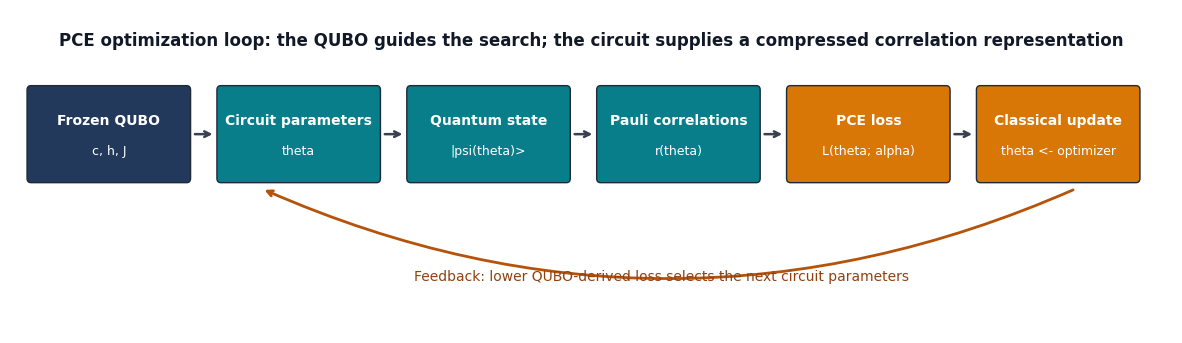

In [31]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch


def draw_pce_workflow() -> None:
    """Draw the PCE feedback loop and where the QUBO guides the search."""

    steps = [
        ('Frozen QUBO', 'c, h, J'),
        ('Circuit parameters', 'theta'),
        ('Quantum state', '|psi(theta)>'),
        ('Pauli correlations', 'r(theta)'),
        ('PCE loss', 'L(theta; alpha)'),
        ('Classical update', 'theta <- optimizer'),
    ]
    colors = ['#23395B', '#087E8B', '#087E8B', '#087E8B', '#D97706', '#D97706']
    fig, ax = plt.subplots(figsize=(15, 4.2))
    ax.set_xlim(0, 15)
    ax.set_ylim(-1.2, 2.5)
    ax.axis('off')

    for index, ((title, detail), color) in enumerate(zip(steps, colors, strict=True)):
        x = 0.25 + index * 2.45
        box = FancyBboxPatch(
            (x, 0.55), 2.05, 1.05,
            boxstyle='round,pad=0.03,rounding_size=0.05',
            facecolor=color, edgecolor='#1F2937', linewidth=1.0,
        )
        ax.add_patch(box)
        ax.text(x + 1.025, 1.23, title, ha='center', va='center', color='white',
                fontsize=10, fontweight='bold')
        ax.text(x + 1.025, 0.88, detail, ha='center', va='center', color='white', fontsize=9)
        if index < len(steps) - 1:
            ax.annotate('', xy=(x + 2.4, 1.075), xytext=(x + 2.1, 1.075),
                        arrowprops={'arrowstyle': '->', 'color': '#374151', 'lw': 1.8})

    ax.annotate(
        '', xy=(3.25, 0.45), xytext=(13.75, 0.45),
        arrowprops={'arrowstyle': '->', 'connectionstyle': 'arc3,rad=-0.22',
                    'color': '#B45309', 'lw': 2.0},
    )
    ax.text(8.4, -0.56, 'Feedback: lower QUBO-derived loss selects the next circuit parameters',
            ha='center', va='center', color='#92400E', fontsize=10)
    ax.text(7.5, 2.15, 'PCE optimization loop: the QUBO guides the search; the circuit supplies a compressed correlation representation',
            ha='center', va='center', color='#111827', fontsize=12, fontweight='bold')
    plt.show()


draw_pce_workflow()


### PCE objective

The circuit prepares correlations; it does not implement the QUBO as gates. The frozen QUBO enters through the Ising coefficients $c$, $h_i$, and $J_{ij}$. PCE transforms each measured correlation into a soft spin:

$$
u_i(\theta;\alpha)=\tanh(\alpha r_i(\theta)),
$$

It then evaluates the QUBO-derived objective:

$$
\mathcal{L}_{\mathrm{PCE}}(\theta;\alpha)
=c+\sum_{i=0}^{m-1} h_i u_i(\theta;\alpha)
+\sum_{0\leq i<j\leq m-1} J_{ij}u_i(\theta;\alpha)u_j(\theta;\alpha).
$$

Assignment and GPU-capacity penalties are already embedded in these coefficients. This is a correlation-based relaxation: it uses $u_i u_j$, not $\langle\Pi_i\Pi_j\rangle$, so decoded schedules must still be validated.


### How the QUBO guides the parameter update

For one soft spin $u_l$, holding the other soft spins fixed, define its effective field:

$$
g_l=h_l+\sum_{j\ne l}J_{lj}u_j.
$$

Its local contribution to the loss is $u_l g_l$, so minimization prefers $u_l$ to have the opposite sign of $g_l$. This gives three useful interpretations:

- **Local field:** if $h_l>0$, the loss favors $u_l=-1$; if $h_l<0$, it favors $u_l=+1$. Energy coefficients and penalty terms both contribute to this preference.
- **Coupling:** if $J_{lj}>0$, the loss favors opposite signs for $u_l$ and $u_j$; if $J_{lj}<0$, it favors equal signs. A positive coupling between two possible starts of the same job helps prevent both starts being selected.
- **Trade-off:** a strong coupling can override a local preference. The update must improve the total scheduling loss, not each logical variable independently.

The optimizer changes $\theta$, not $u_l$ directly. Through the circuit, one parameter update changes several correlations at once. The ansatz therefore supplies a compressed correlated search space, while $h_i$ and $J_{ij}$ provide the problem-specific direction. This can help or hurt; it must be compared with random and classical baselines.


## Step 6: minimize the PCE objective and decode a schedule

This experiment sweeps several fixed binarization values $\alpha$ using COBYLA, a derivative-free classical optimizer. Every alpha value starts from the same initial circuit parameters and receives the same evaluation budget. For every proposed $\theta$, the workflow evaluates all Pauli correlations, computes the PCE objective, and records the decoded binary schedule.

The optimization target is the continuous PCE loss. The decoded bitstring is a diagnostic output, not a hidden repair: it is checked with the project schedule validator exactly as returned. This is a fixed-alpha sensitivity study, not progressive binarization. The separate PB-PCE section below adds adaptive-alpha continuation; multiple random seeds remain future experimental work.


In [32]:
PCE_ALPHA_VALUES = [0.5, 1.0, 2.0, 4.0, 8.0]
PCE_MAXITER = 120
PCE_SEED = 2026


def pce_soft_spins(theta: np.ndarray, alpha: float) -> tuple[np.ndarray, np.ndarray]:
    """Return Pauli correlations and their tanh-binarized soft spins."""

    correlations = evaluate_pce_correlations(theta, ansatz, ansatz_parameters, full_labels)
    return correlations, np.tanh(alpha * correlations)


def pce_loss_from_soft_spins(soft_spins: np.ndarray) -> float:
    """Evaluate the full Ising-derived PCE loss before binary decoding."""

    return float(
        ising_constant
        + soft_spins @ ising_fields
        + np.sum(
            ising_couplings
            * soft_spins[coupling_left]
            * soft_spins[coupling_right]
        )
    )


def decode_soft_spins(soft_spins: np.ndarray) -> np.ndarray:
    """Decode non-negative soft spins to selected QUBO bits."""

    spins = np.where(np.asarray(soft_spins) >= 0.0, 1, -1)
    return ((spins + 1) // 2).astype(int)


def evaluate_decoded_candidate(theta: np.ndarray, alpha: float) -> dict:
    """Evaluate PCE loss, decode its bitstring, and validate the raw schedule."""

    correlations, soft_spins = pce_soft_spins(theta, alpha)
    bits = decode_soft_spins(soft_spins)
    schedule = decode_qubo_sample(qubo, bits)
    validation = validate_decoded_schedule(
        schedule, jobs, clusters, [int(hour) for hour in qubo.metadata['hours']]
    )
    return {
        'theta': np.asarray(theta).copy(),
        'correlations': correlations,
        'soft_spins': soft_spins,
        'bits': bits,
        'pce_loss': pce_loss_from_soft_spins(soft_spins),
        'qubo_energy': qubo_energy(qubo, bits),
        'schedule': schedule,
        'validation': validation,
    }


rng = np.random.default_rng(PCE_SEED)
initial_theta = rng.uniform(-np.pi, np.pi, size=len(ansatz_parameters))
ising_loss_scale = max(
    1.0,
    abs(ising_constant) + np.abs(ising_fields).sum() + np.abs(ising_couplings).sum(),
)


def run_fixed_alpha(alpha: float, initial_theta: np.ndarray) -> dict:
    """Optimize one fixed-alpha PCE run from a shared initial state."""

    history = []
    best_physical_candidate = None

    def objective(theta: np.ndarray) -> float:
        nonlocal best_physical_candidate
        candidate = evaluate_decoded_candidate(theta, alpha)
        validation = candidate['validation']
        history.append({
            'evaluation': len(history) + 1,
            'pce_loss': candidate['pce_loss'],
            'qubo_energy': candidate['qubo_energy'],
            'physical_feasible': validation['feasible'],
            'violation_count': len(validation['violations']),
        })
        if validation['feasible'] and (
            best_physical_candidate is None
            or candidate['qubo_energy'] < best_physical_candidate['qubo_energy']
        ):
            best_physical_candidate = candidate
        return candidate['pce_loss'] / ising_loss_scale

    optimization = minimize(
        objective, initial_theta, method='COBYLA',
        options={'maxiter': PCE_MAXITER, 'rhobeg': 0.5, 'tol': 1e-5},
    )
    final_candidate = evaluate_decoded_candidate(optimization.x, alpha)
    return {
        'alpha': alpha,
        'optimization': optimization,
        'history': pd.DataFrame(history),
        'selected_candidate': best_physical_candidate or final_candidate,
        'selected_from_feasible_trace': best_physical_candidate is not None,
    }


alpha_runs = [run_fixed_alpha(alpha, initial_theta) for alpha in PCE_ALPHA_VALUES]
alpha_summary = pd.DataFrame([{
    'alpha': run['alpha'],
    'optimizer_success': bool(run['optimization'].success),
    'optimizer_evaluations': len(run['history']),
    'selected_from_feasible_trace': run['selected_from_feasible_trace'],
    'PCE_loss': run['selected_candidate']['pce_loss'],
    'decoded_QUBO_energy': run['selected_candidate']['qubo_energy'],
    'physical_feasible': run['selected_candidate']['validation']['feasible'],
    'violation_count': len(run['selected_candidate']['validation']['violations']),
} for run in alpha_runs])
display(alpha_summary)

feasible_runs = [run for run in alpha_runs if run['selected_candidate']['validation']['feasible']]
selected_run = min(
    feasible_runs or alpha_runs,
    key=lambda run: run['selected_candidate']['qubo_energy'] if feasible_runs else run['selected_candidate']['pce_loss'],
)
selected_candidate = selected_run['selected_candidate']
if feasible_runs:
    print(f"Selected feasible alpha: {selected_run['alpha']}")
else:
    print(f"No feasible fixed-alpha candidate. Lowest relaxed-loss alpha: {selected_run['alpha']}")
display(selected_run['history'].tail(10))
display(selected_candidate['schedule'])
print('Validation:', selected_candidate['validation'])


# Re-run the fixed-alpha protocol for every available ansatz. The QUBO,
# Pauli allocation, alpha grid, seed, and optimizer budget remain fixed.
def evaluate_candidate_for_ansatz(
    theta: np.ndarray,
    alpha: float,
    circuit: QuantumCircuit,
    parameters: list,
) -> dict:
    """Evaluate and validate one PCE candidate for an explicit circuit."""

    correlations = evaluate_pce_correlations(theta, circuit, parameters, full_labels)
    soft_spins = np.tanh(alpha * correlations)
    bits = decode_soft_spins(soft_spins)
    schedule = decode_qubo_sample(qubo, bits)
    validation = validate_decoded_schedule(
        schedule, jobs, clusters, [int(hour) for hour in qubo.metadata['hours']]
    )
    return {
        'theta': np.asarray(theta).copy(),
        'correlations': correlations,
        'soft_spins': soft_spins,
        'bits': bits,
        'pce_loss': pce_loss_from_soft_spins(soft_spins),
        'qubo_energy': qubo_energy(qubo, bits),
        'schedule': schedule,
        'validation': validation,
    }


def run_fixed_alpha_for_ansatz(ansatz_id: str) -> dict:
    """Run the same fixed-alpha experiment for one named ansatz."""

    details = ANSATZ_BUILDERS[ansatz_id]
    circuit, parameters = details['builder'](full_pce_qubits, PCE_LAYERS)
    theta0 = np.random.default_rng(PCE_SEED).uniform(
        -np.pi, np.pi, size=len(parameters)
    )
    alpha_runs = []

    for alpha in PCE_ALPHA_VALUES:
        history = []
        best_physical_candidate = None

        def objective(theta: np.ndarray) -> float:
            nonlocal best_physical_candidate
            candidate = evaluate_candidate_for_ansatz(theta, alpha, circuit, parameters)
            validation = candidate['validation']
            history.append({
                'evaluation': len(history) + 1,
                'pce_loss': candidate['pce_loss'],
                'qubo_energy': candidate['qubo_energy'],
                'physical_feasible': validation['feasible'],
                'violation_count': len(validation['violations']),
            })
            if validation['feasible'] and (
                best_physical_candidate is None
                or candidate['qubo_energy'] < best_physical_candidate['qubo_energy']
            ):
                best_physical_candidate = candidate
            return candidate['pce_loss'] / ising_loss_scale

        optimization = minimize(
            objective, theta0, method='COBYLA',
            options={'maxiter': PCE_MAXITER, 'rhobeg': 0.5, 'tol': 1e-5},
        )
        final_candidate = evaluate_candidate_for_ansatz(
            optimization.x, alpha, circuit, parameters
        )
        alpha_runs.append({
            'alpha': alpha,
            'optimization': optimization,
            'history': pd.DataFrame(history),
            'selected_candidate': best_physical_candidate or final_candidate,
            'selected_from_feasible_trace': best_physical_candidate is not None,
        })

    feasible_runs = [
        run for run in alpha_runs if run['selected_candidate']['validation']['feasible']
    ]
    selected_run = min(
        feasible_runs or alpha_runs,
        key=lambda run: (
            run['selected_candidate']['qubo_energy']
            if feasible_runs else run['selected_candidate']['pce_loss']
        ),
    )
    return {
        'ansatz_id': ansatz_id,
        'circuit': circuit,
        'parameters': parameters,
        'alpha_runs': alpha_runs,
        'selected_run': selected_run,
        'selected_candidate': selected_run['selected_candidate'],
        'any_feasible': bool(feasible_runs),
    }


ansatz_fixed_alpha_runs = {
    ansatz_id: run_fixed_alpha_for_ansatz(ansatz_id)
    for ansatz_id in ANSATZ_BUILDERS
}
ansatz_comparison_summary = pd.DataFrame([
    {
        'ansatz_id': ansatz_id,
        'parameters': len(result['parameters']),
        'depth': result['circuit'].depth(),
        'hardware_ready': ANSATZ_BUILDERS[ansatz_id]['hardware_ready'],
        'selected_alpha': result['selected_run']['alpha'],
        'any_feasible_alpha': result['any_feasible'],
        'selected_QUBO_energy': result['selected_candidate']['qubo_energy'],
        'selected_PCE_loss': result['selected_candidate']['pce_loss'],
        'selected_violation_count': len(result['selected_candidate']['validation']['violations']),
    }
    for ansatz_id, result in ansatz_fixed_alpha_runs.items()
])
display(ansatz_comparison_summary)

# This is intentionally separate from SELECTED_ANSATZ_ID: the primary notebook
# walkthrough may use a statevector reference, while IBM must use brickwork.
QPU_ANSATZ_ID = 'legacy_chain_ry_rz_cx_v1'
qpu_reference = ansatz_fixed_alpha_runs[QPU_ANSATZ_ID]
qpu_selected_run = qpu_reference['selected_run']
qpu_selected_candidate = qpu_reference['selected_candidate']
print(
    f'QPU reference: {QPU_ANSATZ_ID}; alpha={qpu_selected_run["alpha"]}; '
    f'feasible={qpu_selected_candidate["validation"]["feasible"]}'
)


,alpha,optimizer_success,optimizer_evaluations,selected_from_feasible_trace,PCE_loss,decoded_QUBO_energy,physical_feasible,violation_count
0,0.5,False,120,False,12023.138792,2386.448,False,2
1,1.0,False,120,False,8944.744990,3388.040,False,3
2,2.0,False,120,True,7485.136511,271.448,True,0
3,4.0,False,120,True,4352.526314,198.448,True,0
4,8.0,False,120,False,2371.399085,2254.448,False,2


Selected feasible alpha: 4.0


,evaluation,pce_loss,qubo_energy,physical_feasible,violation_count
110,111,3385.368638,271.448,True,0
111,112,3463.935293,1498.856,False,2
112,113,3866.986530,271.448,True,0
113,114,3653.548095,271.448,True,0
114,115,3404.625117,271.448,True,0
115,116,3451.541636,271.448,True,0
116,117,3511.059389,271.448,True,0
117,118,3464.841478,271.448,True,0
118,119,3483.374550,271.448,True,0
119,120,3387.876669,271.448,True,0


,job_id,assigned_cluster,start_hour,duration,power,gpu_count_required,cpu_required,memory_required_gb,qubo_variable
0,seren_pretrain_000,seren_pretrain_pool,13,1,0.0256,1.0,NaN,NaN,0
1,seren_pretrain_001,seren_pretrain_pool,13,1,0.0256,1.0,NaN,NaN,4
2,seren_pretrain_002,seren_pretrain_pool,13,1,0.0256,1.0,NaN,NaN,12
3,seren_pretrain_003,seren_pretrain_pool,13,1,0.0256,1.0,NaN,NaN,13
4,seren_pretrain_004,seren_pretrain_pool,13,1,0.0256,1.0,NaN,NaN,17
5,seren_pretrain_005,seren_pretrain_pool,15,1,0.0256,1.0,NaN,NaN,23


Validation: {'feasible': True, 'violations': []}


,ansatz_id,parameters,depth,hardware_ready,selected_alpha,any_feasible_alpha,selected_QUBO_energy,selected_PCE_loss,selected_violation_count
0,legacy_chain_ry_rz_cx_v1,32,11,True,4.0,True,198.448,4352.526314,0
1,ibm_brickwork_ry_rz_cx_open_v1,16,4,True,8.0,False,2791.264,4386.676687,2
2,taylor_efficient_statevector_v1,12,2,False,8.0,False,21979.936,8500.877770,2


QPU reference: legacy_chain_ry_rz_cx_v1; alpha=4.0; feasible=True


## Step 6a: progressive-binarization PCE (PB-PCE)

The fixed-alpha sweep above identifies sensitivity to alpha, but each run starts from the same initial circuit parameters. PB-PCE instead follows a continuation path: optimize at a small alpha, warm-start the next optimization from the prior parameters, then increase alpha adaptively.

After each stage, let $u_i = \tanh(\alpha r_i)$. If any variable has $|u_i|<M$, the update selects the unbinarized variable closest to $M$ and sets the next alpha so that its current raw correlation would reach $M$ before re-optimization. This is the update rule reported by Padin-Martinez et al. The schedule is still decoded and validated after every stage; binarization alone does not prove feasibility.

This is a statevector experiment. It does not submit QPU jobs. The existing QPU section remains explicitly controlled and can later be pointed at the PB-PCE result after reviewing its statevector validation.


In [33]:
# Match the PB-PCE paper's small-instance initialization; fixed-alpha PCE is feasible at alpha=4 here.
PB_PCE_INITIAL_ALPHA = 3.0
PB_PCE_BINARIZATION_TARGET = 0.90
PB_PCE_MAX_STAGES = 12
PB_PCE_STAGE_MAXITER = 120
PB_PCE_ALPHA_MAX = 1e6


def run_pb_pce(initial_theta: np.ndarray) -> dict:
    """Run adaptive-alpha PCE with warm starts between binarization stages."""

    alpha = float(PB_PCE_INITIAL_ALPHA)
    theta = np.asarray(initial_theta, dtype=float).copy()
    stages = []
    best_feasible_candidate = None

    for stage in range(1, PB_PCE_MAX_STAGES + 1):
        optimization = minimize(
            lambda values: evaluate_decoded_candidate(values, alpha)['pce_loss'] / ising_loss_scale,
            theta,
            method='COBYLA',
            options={'maxiter': PB_PCE_STAGE_MAXITER, 'rhobeg': 0.5, 'tol': 1e-5},
        )
        candidate = evaluate_decoded_candidate(optimization.x, alpha)
        if candidate['validation']['feasible'] and (
            best_feasible_candidate is None
            or candidate['qubo_energy'] < best_feasible_candidate['qubo_energy']
        ):
            best_feasible_candidate = candidate

        magnitudes = np.abs(candidate['soft_spins'])
        unbinarized = np.flatnonzero(magnitudes < PB_PCE_BINARIZATION_TARGET)
        stage_row = {
            'stage': stage,
            'alpha': alpha,
            'optimizer_success': bool(optimization.success),
            'optimizer_evaluations': int(optimization.nfev),
            'PCE_loss': candidate['pce_loss'],
            'decoded_QUBO_energy': candidate['qubo_energy'],
            'physical_feasible': candidate['validation']['feasible'],
            'violation_count': len(candidate['validation']['violations']),
            'binarized_fraction': float(np.mean(magnitudes >= PB_PCE_BINARIZATION_TARGET)),
            'min_soft_spin_magnitude': float(magnitudes.min()),
        }
        stages.append(stage_row)
        theta = optimization.x

        if not len(unbinarized):
            break

        # Paper rule: advance the unbinarized value nearest the target to M.
        target_index = unbinarized[np.argmax(magnitudes[unbinarized])]
        current_magnitude = float(np.clip(magnitudes[target_index], 1e-12, 1.0 - 1e-12))
        alpha_factor = np.arctanh(PB_PCE_BINARIZATION_TARGET) / np.arctanh(current_magnitude)
        next_alpha = min(PB_PCE_ALPHA_MAX, alpha * alpha_factor)
        alpha = max(next_alpha, alpha * 1.01)

    return {
        'stages': pd.DataFrame(stages),
        'final_candidate': candidate,
        'selected_candidate': best_feasible_candidate or candidate,
        'selected_from_feasible_stage': best_feasible_candidate is not None,
    }


pb_pce_run = run_pb_pce(initial_theta)
pb_pce_summary = pb_pce_run['stages']
pb_pce_candidate = pb_pce_run['selected_candidate']
display(pb_pce_summary)
display(pb_pce_candidate['schedule'])
print('PB-PCE validation:', pb_pce_candidate['validation'])


,stage,alpha,optimizer_success,optimizer_evaluations,PCE_loss,decoded_QUBO_energy,physical_feasible,violation_count,binarized_fraction,min_soft_spin_magnitude
0,1,3.000000,False,120,5121.165883,2437.448,False,2,0.061538,0.016470
1,2,3.035329,False,120,3959.184864,1405.040,False,2,0.046154,0.016860
2,3,3.091031,False,120,3504.896901,1405.040,False,2,0.015385,0.041981
3,4,3.140266,False,120,3317.756732,432.448,True,0,0.000000,0.158652
4,5,3.171669,False,120,3177.990546,432.448,True,0,0.030769,0.516641
5,6,3.397994,False,120,2810.162164,432.448,True,0,0.076923,0.572323
6,7,3.466224,False,120,2710.708336,432.448,True,0,0.046154,0.577226
7,8,3.500886,False,120,2659.225055,432.448,True,0,0.046154,0.574550
8,9,3.541945,False,120,2604.344196,432.448,True,0,0.061538,0.593094
9,10,3.577365,False,120,2558.383461,432.448,True,0,0.076923,0.603284


,job_id,assigned_cluster,start_hour,duration,power,gpu_count_required,cpu_required,memory_required_gb,qubo_variable
0,seren_pretrain_002,seren_pretrain_pool,11,1,0.0256,1.0,NaN,NaN,10
1,seren_pretrain_000,seren_pretrain_pool,13,1,0.0256,1.0,NaN,NaN,0
2,seren_pretrain_004,seren_pretrain_pool,13,1,0.0256,1.0,NaN,NaN,17
3,seren_pretrain_001,seren_pretrain_pool,14,1,0.0256,1.0,NaN,NaN,5
4,seren_pretrain_005,seren_pretrain_pool,14,1,0.0256,1.0,NaN,NaN,22
5,seren_pretrain_003,seren_pretrain_pool,15,1,0.0256,1.0,NaN,NaN,15


PB-PCE validation: {'feasible': True, 'violations': []}


### PCE Hamiltonian contribution diagnostic

The full reduced QUBO is additive: energy cost plus assignment penalty plus GPU-capacity-with-slack penalty. A low total PCE loss can hide a poor trade-off between those terms. This diagnostic evaluates each term separately at the soft PCE spins and at the decoded binary sample.

The GPU term is also split structurally into assignment-assignment, assignment-slack, and slack-slack QUBO coefficients. This does not prove causality, but it shows whether the auxiliary slack representation has a larger numerical scale than the business assignment decisions.

The reported `soft_Ising_contribution` is the quantity optimized by PCE. The reported `decoded_QUBO_contribution` is evaluated after sign decoding. Feasibility remains determined from the decoded assignment schedule, not from the slack bits.


In [34]:
def build_component_qubos() -> dict[str, object]:
    """Build additive reduced-QUBO components using the frozen instance inputs."""

    energy_only = build_scheduling_qubo(
        jobs, qubo_energy_inputs, clusters, qubo_config,
        QuboPenaltyWeights(assignment=0.0, gpu_capacity=0.0, peak_smoothing=0.0),
    )
    energy_assignment = build_scheduling_qubo(
        jobs, qubo_energy_inputs, clusters, qubo_config,
        QuboPenaltyWeights(assignment=ASSIGNMENT_WEIGHT, gpu_capacity=0.0, peak_smoothing=0.0),
    )
    energy_gpu = build_scheduling_qubo(
        jobs, qubo_energy_inputs, clusters, qubo_config,
        QuboPenaltyWeights(assignment=0.0, gpu_capacity=GPU_CAPACITY_WEIGHT, peak_smoothing=0.0),
    )
    return {
        'energy': energy_only,
        'energy_plus_assignment': energy_assignment,
        'energy_plus_gpu': energy_gpu,
    }


def relaxed_ising_energy(component_qubo, soft_spins: np.ndarray) -> float:
    """Evaluate one QUBO component after its binary-to-Ising relaxation."""

    constant, fields, left, right, couplings = qubo_to_ising(component_qubo)
    component_spins = np.asarray(soft_spins[:component_qubo.num_variables], dtype=float)
    return float(ising_energy(component_spins, constant, fields, left, right, couplings))


def component_difference(
    upper_qubo,
    lower_qubo,
    bits: np.ndarray,
    soft_spins: np.ndarray,
) -> tuple[float, float]:
    """Return binary-QUBO and relaxed-Ising values for an additive difference."""

    upper_binary = qubo_energy(upper_qubo, bits[:upper_qubo.num_variables])
    lower_binary = qubo_energy(lower_qubo, bits[:lower_qubo.num_variables])
    upper_soft = relaxed_ising_energy(upper_qubo, soft_spins)
    lower_soft = relaxed_ising_energy(lower_qubo, soft_spins)
    return upper_binary - lower_binary, upper_soft - lower_soft


def gpu_coefficient_structure(gpu_qubo) -> pd.DataFrame:
    """Summarize GPU-term coefficient scale by assignment/slack interaction type."""

    groups = {'offset': [gpu_qubo.offset]}
    for index, coefficient in gpu_qubo.linear.items():
        kind = gpu_qubo.variables[index]['variable_type']
        groups.setdefault(f'linear:{kind}', []).append(coefficient)
    for (left, right), coefficient in gpu_qubo.quadratic.items():
        left_kind = gpu_qubo.variables[left]['variable_type']
        right_kind = gpu_qubo.variables[right]['variable_type']
        pair = ':'.join(sorted([left_kind, right_kind]))
        groups.setdefault(f'quadratic:{pair}', []).append(coefficient)

    return pd.DataFrame([
        {
            'coefficient_group': name,
            'count': len(values),
            'max_abs_coefficient': float(np.max(np.abs(values))),
            'sum_abs_coefficients': float(np.sum(np.abs(values))),
        }
        for name, values in groups.items()
    ]).sort_values('sum_abs_coefficients', ascending=False)


component_qubos = build_component_qubos()
energy_qubo = component_qubos['energy']
energy_assignment_qubo = component_qubos['energy_plus_assignment']
energy_gpu_qubo = component_qubos['energy_plus_gpu']


def inspect_pce_contributions(label: str, candidate: dict) -> pd.DataFrame:
    """Display term contributions for one fixed-alpha or PB-PCE candidate."""

    bits = np.asarray(candidate['bits'], dtype=int)
    soft_spins = np.asarray(candidate['soft_spins'], dtype=float)
    energy_binary = qubo_energy(energy_qubo, bits[:energy_qubo.num_variables])
    energy_soft = relaxed_ising_energy(energy_qubo, soft_spins)
    assignment_binary, assignment_soft = component_difference(
        energy_assignment_qubo, energy_qubo, bits, soft_spins
    )
    gpu_binary, gpu_soft = component_difference(
        energy_gpu_qubo, energy_qubo, bits, soft_spins
    )
    rows = [
        {
            'candidate': label,
            'term': 'energy',
            'decoded_QUBO_contribution': energy_binary,
            'soft_Ising_contribution': energy_soft,
        },
        {
            'candidate': label,
            'term': 'assignment_penalty',
            'decoded_QUBO_contribution': assignment_binary,
            'soft_Ising_contribution': assignment_soft,
        },
        {
            'candidate': label,
            'term': 'GPU_capacity_with_slack_penalty',
            'decoded_QUBO_contribution': gpu_binary,
            'soft_Ising_contribution': gpu_soft,
        },
    ]
    result = pd.DataFrame(rows)
    result['abs_soft_contribution'] = result['soft_Ising_contribution'].abs()
    return result


contribution_summary = pd.concat([
    inspect_pce_contributions('fixed_alpha_selected', selected_candidate),
    inspect_pce_contributions('PB_PCE_selected', pb_pce_candidate),
], ignore_index=True)
display(contribution_summary)

gpu_structure = gpu_coefficient_structure(energy_gpu_qubo)
display(gpu_structure)

print('Full-QUBO decoded energy check:')
for label, candidate in [('fixed_alpha_selected', selected_candidate), ('PB_PCE_selected', pb_pce_candidate)]:
    reconstructed = contribution_summary.loc[
        contribution_summary['candidate'] == label, 'decoded_QUBO_contribution'
    ].sum()
    print(f'{label}: reconstructed={reconstructed:.6f}, full={candidate["qubo_energy"]:.6f}')


,candidate,term,decoded_QUBO_contribution,soft_Ising_contribution,abs_soft_contribution
0,fixed_alpha_selected,energy,8.448000e+00,11.130674,11.130674
1,fixed_alpha_selected,assignment_penalty,3.197442e-13,3886.602973,3886.602973
2,fixed_alpha_selected,GPU_capacity_with_slack_penalty,1.900000e+02,454.792667,454.792667
3,PB_PCE_selected,energy,8.448000e+00,9.741963,9.741963
4,PB_PCE_selected,assignment_penalty,3.197442e-13,2863.230749,2863.230749
5,PB_PCE_selected,GPU_capacity_with_slack_penalty,4.240000e+02,444.784021,444.784021


,coefficient_group,count,max_abs_coefficient,sum_abs_coefficients
2,linear:gpu_slack,40,480.000,8680.0
4,quadratic:gpu_slack:gpu_slack,80,256.000,4960.0
0,offset,1,4232.000,4232.0
3,quadratic:assignment:gpu_slack,125,32.000,1550.0
1,linear:assignment,25,43.592,1089.8
5,quadratic:assignment:assignment,41,2.000,82.0


Full-QUBO decoded energy check:
fixed_alpha_selected: reconstructed=198.448000, full=198.448000
PB_PCE_selected: reconstructed=432.448000, full=432.448000


## Step 6b: execute the selected PCE configuration on an IBM QPU

This section executes the same ansatz and Pauli-observable map on IBM hardware. It does not submit a QAOA cost circuit: the QPU estimates PCE correlations, while the notebook evaluates the PCE loss and decodes the schedule.

Create a local `.env` from `.env.example` and provide `QISKIT_IBM_TOKEN`. `QISKIT_IBM_INSTANCE` should contain the CRN or instance name when a specific Quantum Compute instance is available; this is recommended so the selected access plan is unambiguous. The `.env` file is ignored by Git.

The section is disabled by default. It checks the QPU width against the PCE register derived from the selected instance, so the same notebook supports larger compatible instances. Enable it only after the chosen statevector configuration has produced a feasible schedule. SPSA refinement is optional because every additional iteration submits further QPU jobs.


In [35]:
import os

from dotenv import load_dotenv
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2, QiskitRuntimeService

load_dotenv(ROOT / '.env', override=False)

# Safety controls: no QPU job is submitted until RUN_ON_QPU is explicitly enabled.
RUN_ON_QPU = os.getenv('RUN_ON_QPU', 'false').lower() == 'true'
QPU_DRY_RUN = False  # The public EstimatorV2 interface does not provide dry-run submissions.
IBM_BACKEND_NAME = os.getenv('IBM_BACKEND_NAME') or None  # Override automatic least-busy selection.
QPU_PRECISION = 0.03
QPU_EXECUTION_MODE = os.getenv('PCE_QPU_MODE', 'fixed_alpha')  # 'fixed_alpha' or 'pb_pce'
QPU_SPSA_ITERATIONS = 0  # Optional refinement only for fixed_alpha.
QPU_PB_SPSA_ITERATIONS = 0  # Per PB stage. Set explicitly before a hardware PB run.
QPU_PB_MAX_STAGES = 12
QPU_SPSA_SEED = 2027
PCE_ANSATZ_ID = QPU_ANSATZ_ID

if not ANSATZ_BUILDERS[PCE_ANSATZ_ID]['hardware_ready']:
    raise RuntimeError('QPU_ANSATZ_ID must select an IBM-compatible ansatz.')

hardware_ansatz = qpu_reference['circuit']
hardware_ansatz_parameters = qpu_reference['parameters']


def pce_candidate_from_correlations(
    correlations: np.ndarray, theta: np.ndarray, alpha: float
) -> dict:
    """Decode measured PCE correlations with the shared local validation logic."""

    soft_spins = np.tanh(alpha * np.asarray(correlations, dtype=float))
    bits = decode_soft_spins(soft_spins)
    schedule = decode_qubo_sample(qubo, bits)
    validation = validate_decoded_schedule(
        schedule, jobs, clusters, [int(hour) for hour in qubo.metadata['hours']]
    )
    return {
        'theta': np.asarray(theta).copy(),
        'correlations': np.asarray(correlations, dtype=float),
        'soft_spins': soft_spins,
        'bits': bits,
        'pce_loss': pce_loss_from_soft_spins(soft_spins),
        'qubo_energy': qubo_energy(qubo, bits),
        'schedule': schedule,
        'validation': validation,
    }


def create_ibm_service() -> QiskitRuntimeService:
    """Create a service without exposing credentials in the notebook."""

    token = os.getenv('QISKIT_IBM_TOKEN')
    instance = os.getenv('QISKIT_IBM_INSTANCE')
    if not token:
        raise RuntimeError('QISKIT_IBM_TOKEN is missing. Add it to the local .env file.')
    options = {'channel': 'ibm_quantum_platform', 'token': token}
    if instance:
        options['instance'] = instance
    return QiskitRuntimeService(**options)


def select_qpu_backend(service: QiskitRuntimeService):
    """Select the requested backend or an available QPU wide enough for PCE."""

    if IBM_BACKEND_NAME:
        backend = service.backend(IBM_BACKEND_NAME)
    else:
        backend = service.least_busy(
            operational=True, simulator=False, min_num_qubits=full_pce_qubits
        )
    if backend.num_qubits < full_pce_qubits:
        raise ValueError(
            f'Backend {backend.name} has {backend.num_qubits} qubits; '
            f'the selected instance requires {full_pce_qubits} PCE qubits.'
        )
    return backend


def build_qpu_correlation_evaluator(backend):
    """Transpile once and return a callable that estimates all PCE correlations."""

    pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_ansatz = pass_manager.run(hardware_ansatz)
    isa_observables = [
        SparsePauliOp(label).apply_layout(isa_ansatz.layout)
        for label in full_labels
    ]
    estimator = EstimatorV2(mode=backend)
    estimator.options.default_precision = QPU_PRECISION

    def evaluate(theta: np.ndarray) -> tuple[np.ndarray, str]:
        if QPU_DRY_RUN:
            raise RuntimeError(
                'QPU_DRY_RUN is unavailable with the public EstimatorV2 API. '
                'Keep RUN_ON_QPU disabled to inspect the setup without submitting a job.'
            )
        job = estimator.run(
            [(isa_ansatz, isa_observables, [np.asarray(theta, dtype=float)])]
        )
        result = job.result()[0]
        correlations = np.asarray(result.data.evs, dtype=float).reshape(-1)
        if correlations.shape != (qubo.num_variables,):
            raise RuntimeError(
                f'Expected {qubo.num_variables} correlations, received {correlations.shape}'
            )
        return correlations, job.job_id()

    return evaluate, isa_ansatz


def refine_with_hardware_spsa(evaluate, theta: np.ndarray, alpha: float) -> tuple[dict, list[dict]]:
    """Run a small two-evaluation-per-iteration SPSA refinement on the QPU."""

    rng = np.random.default_rng(QPU_SPSA_SEED)
    theta = np.asarray(theta, dtype=float).copy()
    best_candidate = None
    trace = []
    for iteration in range(QPU_SPSA_ITERATIONS):
        step = 0.20 / (iteration + 1) ** 0.602
        perturbation = 0.15 / (iteration + 1) ** 0.101
        delta = rng.choice([-1.0, 1.0], size=len(theta))
        plus_correlations, plus_job_id = evaluate(theta + perturbation * delta)
        minus_correlations, minus_job_id = evaluate(theta - perturbation * delta)
        plus = pce_candidate_from_correlations(plus_correlations, theta + perturbation * delta, alpha)
        minus = pce_candidate_from_correlations(minus_correlations, theta - perturbation * delta, alpha)
        gradient = (plus['pce_loss'] - minus['pce_loss']) * delta / (2.0 * perturbation)
        theta -= step * gradient / ising_loss_scale
        for candidate, job_id in [(plus, plus_job_id), (minus, minus_job_id)]:
            candidate['job_id'] = job_id
            if best_candidate is None or candidate['pce_loss'] < best_candidate['pce_loss']:
                best_candidate = candidate
        trace.append({
            'iteration': iteration + 1,
            'plus_job_id': plus_job_id,
            'minus_job_id': minus_job_id,
            'plus_loss': plus['pce_loss'],
            'minus_loss': minus['pce_loss'],
        })
    return best_candidate, trace



def run_pb_pce_on_qpu(evaluate, initial_theta: np.ndarray) -> tuple[dict, list[dict]]:
    """Run hardware-in-the-loop PB-PCE using SPSA at each continuation stage.

    Each SPSA iteration consumes two QPU correlation evaluations. This routine is
    intentionally opt-in because the total hardware cost is approximately
    ``2 * QPU_PB_SPSA_ITERATIONS * QPU_PB_MAX_STAGES`` estimator submissions.
    """

    if QPU_PB_SPSA_ITERATIONS < 1:
        raise ValueError(
            'Set QPU_PB_SPSA_ITERATIONS >= 1 before requesting hardware PB-PCE.'
        )

    alpha = float(PB_PCE_INITIAL_ALPHA)
    theta = np.asarray(initial_theta, dtype=float).copy()
    best_feasible = None
    stages = []

    for stage in range(1, QPU_PB_MAX_STAGES + 1):
        stage_candidate, stage_trace = refine_with_hardware_spsa(
            evaluate, theta, alpha
        )
        if stage_candidate is None:
            raise RuntimeError('Hardware SPSA did not produce a candidate.')
        if stage_candidate['validation']['feasible'] and (
            best_feasible is None
            or stage_candidate['qubo_energy'] < best_feasible['qubo_energy']
        ):
            best_feasible = stage_candidate

        magnitudes = np.abs(stage_candidate['soft_spins'])
        unbinarized = np.flatnonzero(magnitudes < PB_PCE_BINARIZATION_TARGET)
        stages.append({
            'stage': stage,
            'alpha': alpha,
            'pce_loss': stage_candidate['pce_loss'],
            'qubo_energy': stage_candidate['qubo_energy'],
            'physical_feasible': stage_candidate['validation']['feasible'],
            'violation_count': len(stage_candidate['validation']['violations']),
            'binarized_fraction': float(np.mean(magnitudes >= PB_PCE_BINARIZATION_TARGET)),
            'qpu_evaluations': len(stage_trace) * 2,
        })
        theta = stage_candidate['theta']
        if not len(unbinarized):
            break

        # PB-PCE Algorithm 1: choose the unbinarized value closest to M.
        target_index = unbinarized[np.argmax(magnitudes[unbinarized])]
        current_magnitude = float(np.clip(magnitudes[target_index], 1e-12, 1.0 - 1e-12))
        alpha_factor = (
            np.arctanh(PB_PCE_BINARIZATION_TARGET)
            / np.arctanh(current_magnitude)
        )
        alpha = min(PB_PCE_ALPHA_MAX, max(alpha * alpha_factor, alpha * 1.01))

    return {
        'candidate': best_feasible or stage_candidate,
        'stages': stages,
        'alpha': alpha,
    }, stages

hardware_result = None
if not RUN_ON_QPU:
    print('QPU execution is disabled. Configure .env, review the selected backend, then set RUN_ON_QPU = True.')
else:
    if QPU_EXECUTION_MODE not in {'fixed_alpha', 'pb_pce'}:
        raise ValueError("PCE_QPU_MODE must be 'fixed_alpha' or 'pb_pce'.")
    if QPU_EXECUTION_MODE == 'fixed_alpha' and not qpu_selected_candidate['validation']['feasible']:
        raise RuntimeError(
            'The selected fixed-alpha statevector candidate is infeasible. '
            'Do not submit it to the QPU as a hardware-comparison baseline.'
        )
    if QPU_EXECUTION_MODE == 'pb_pce' and not pb_pce_candidate['validation']['feasible']:
        raise RuntimeError(
            'The statevector PB-PCE run is currently infeasible. Improve PB-PCE in '
            'simulation before spending QPU time on a hardware-in-the-loop run.'
        )

    service = create_ibm_service()
    backend = select_qpu_backend(service)
    evaluate_qpu, isa_ansatz = build_qpu_correlation_evaluator(backend)

    if QPU_EXECUTION_MODE == 'fixed_alpha':
        hardware_correlations, hardware_job_id = evaluate_qpu(qpu_selected_candidate['theta'])
        hardware_candidate = pce_candidate_from_correlations(
            hardware_correlations, qpu_selected_candidate['theta'], qpu_selected_run['alpha']
        )
        hardware_candidate['job_id'] = hardware_job_id
        if QPU_SPSA_ITERATIONS > 0:
            refined_candidate, spsa_trace = refine_with_hardware_spsa(
                evaluate_qpu, qpu_selected_candidate['theta'], qpu_selected_run['alpha']
            )
            if refined_candidate['pce_loss'] < hardware_candidate['pce_loss']:
                hardware_candidate = refined_candidate
        else:
            spsa_trace = []
        hardware_alpha = qpu_selected_run['alpha']
    else:
        rng = np.random.default_rng(PCE_SEED)
        pb_initial_theta = rng.uniform(
            -np.pi, np.pi, size=len(hardware_ansatz_parameters)
        )
        pb_hardware_result, spsa_trace = run_pb_pce_on_qpu(
            evaluate_qpu, pb_initial_theta
        )
        hardware_candidate = pb_hardware_result['candidate']
        hardware_alpha = pb_hardware_result['alpha']
        hardware_candidate['job_id'] = None

    hardware_result = {
        'backend': backend.name,
        'backend_qubits': backend.num_qubits,
        'transpiled_depth': isa_ansatz.depth(),
        'ansatz_id': PCE_ANSATZ_ID,
        'execution_mode': QPU_EXECUTION_MODE,
        'job_id': hardware_candidate['job_id'],
        'dry_run': QPU_DRY_RUN,
        'alpha': hardware_alpha,
        'candidate': hardware_candidate,
        'spsa_trace': spsa_trace,
    }
    artifact_directory = ROOT / 'data' / 'results' / 'pce_qpu'
    artifact_directory.mkdir(parents=True, exist_ok=True)
    artifact_path = artifact_directory / f"{hardware_result['job_id']}_correlations.csv"
    artifact = full_pauli_mapping.copy()
    artifact['statevector_correlation'] = evaluate_pce_correlations(
        qpu_selected_candidate['theta'], hardware_ansatz, hardware_ansatz_parameters, full_labels
    )
    artifact['hardware_correlation'] = hardware_candidate['correlations']
    artifact['alpha'] = hardware_result['alpha']
    artifact['backend'] = hardware_result['backend']
    artifact['ansatz_id'] = hardware_result['ansatz_id']
    artifact['job_id'] = hardware_result['job_id']
    artifact.to_csv(artifact_path, index=False)
    hardware_result['artifact_path'] = artifact_path
    display(pd.DataFrame([{
        'backend': hardware_result['backend'],
        'backend_qubits': hardware_result['backend_qubits'],
        'transpiled_depth': hardware_result['transpiled_depth'],
        'job_id': hardware_result['job_id'],
        'alpha': hardware_result['alpha'],
        'PCE_loss': hardware_candidate['pce_loss'],
        'decoded_QUBO_energy': hardware_candidate['qubo_energy'],
        'physical_feasible': hardware_candidate['validation']['feasible'],
        'violation_count': len(hardware_candidate['validation']['violations']),
    }]))
    display(hardware_candidate['schedule'])
    print('Validation:', hardware_candidate['validation'])


QPU execution is disabled. Configure .env, review the selected backend, then set RUN_ON_QPU = True.


A hardware run is only comparable with the statevector reference when `QPU_DRY_RUN=False`. IBM dry-run returns mock values and should be used only to validate submission configuration. For a first paid or queued QPU experiment, keep `QPU_SPSA_ITERATIONS=0` and evaluate the selected statevector parameters once.


## Step 6c: diagnose hardware correlation error

A decoded schedule can change when a hardware correlation crosses zero, because sign decoding maps positive and negative soft spins to different QUBO bits. This diagnostic compares the exact statevector correlations with the QPU correlations for the same selected $\theta$ and alpha.

It reports absolute error, sign flips, and correlations with a small statevector margin. The latter are particularly sensitive to sampling noise and device error. The section can analyze the current in-memory hardware result or retrieve a completed IBM job by setting `IBM_JOB_ID_TO_ANALYZE` in `.env`. Retrieving a result does not submit another QPU job.


In [36]:
IBM_JOB_ID_TO_ANALYZE = os.getenv('IBM_JOB_ID_TO_ANALYZE')
IBM_JOB_ANSATZ_ID = os.getenv('IBM_JOB_ANSATZ_ID')
STATEVECTOR_MARGIN = 0.10


def load_completed_hardware_correlations(job_id: str) -> np.ndarray:
    """Retrieve completed Estimator expectation values without submitting a new job."""

    service = create_ibm_service()
    result = service.job(job_id).result()[0]
    correlations = np.asarray(result.data.evs, dtype=float).reshape(-1)
    if correlations.shape != (qubo.num_variables,):
        raise RuntimeError(
            f'Job {job_id} returned {correlations.shape}; expected {qubo.num_variables} values.'
        )
    return correlations


if hardware_result is not None:
    diagnostic_correlations = hardware_result['candidate']['correlations']
    diagnostic_job_id = hardware_result['job_id']
elif IBM_JOB_ID_TO_ANALYZE and IBM_JOB_ANSATZ_ID == PCE_ANSATZ_ID:
    diagnostic_correlations = load_completed_hardware_correlations(IBM_JOB_ID_TO_ANALYZE)
    diagnostic_job_id = IBM_JOB_ID_TO_ANALYZE
elif IBM_JOB_ID_TO_ANALYZE:
    diagnostic_correlations = None
    diagnostic_job_id = None
    print('Skipped historical QPU job: set IBM_JOB_ANSATZ_ID to the current PCE_ANSATZ_ID only when the circuit matches.')
else:
    diagnostic_correlations = None
    diagnostic_job_id = None

if diagnostic_correlations is None:
    print('No hardware result is available. Run Step 6b or set IBM_JOB_ID_TO_ANALYZE in .env.')
else:
    statevector_correlations = evaluate_pce_correlations(
        qpu_selected_candidate['theta'], hardware_ansatz, hardware_ansatz_parameters, full_labels
    )
    hardware_candidate_for_diagnostics = pce_candidate_from_correlations(
        diagnostic_correlations, qpu_selected_candidate['theta'], qpu_selected_run['alpha']
    )
    correlation_diagnostics = full_pauli_mapping.copy()
    correlation_diagnostics['statevector'] = statevector_correlations
    correlation_diagnostics['hardware'] = diagnostic_correlations
    correlation_diagnostics['absolute_error'] = np.abs(
        correlation_diagnostics['hardware'] - correlation_diagnostics['statevector']
    )
    correlation_diagnostics['statevector_near_zero'] = (
        np.abs(correlation_diagnostics['statevector']) < STATEVECTOR_MARGIN
    )
    correlation_diagnostics['sign_flip'] = (
        (correlation_diagnostics['statevector'] >= 0.0)
        != (correlation_diagnostics['hardware'] >= 0.0)
    )

    diagnostic_summary = pd.DataFrame([{
        'job_id': diagnostic_job_id,
        'variables': len(correlation_diagnostics),
        'mean_absolute_error': correlation_diagnostics['absolute_error'].mean(),
        'root_mean_square_error': np.sqrt(
            np.mean((correlation_diagnostics['hardware'] - correlation_diagnostics['statevector']) ** 2)
        ),
        'sign_flips': int(correlation_diagnostics['sign_flip'].sum()),
        'assignment_sign_flips': int(correlation_diagnostics.loc[
            correlation_diagnostics['variable_type'] == 'assignment', 'sign_flip'
        ].sum()),
        'near_zero_statevector': int(correlation_diagnostics['statevector_near_zero'].sum()),
        'statevector_feasible': qpu_selected_candidate['validation']['feasible'],
        'hardware_feasible': hardware_candidate_for_diagnostics['validation']['feasible'],
    }])
    display(diagnostic_summary)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].scatter(
        correlation_diagnostics['statevector'], correlation_diagnostics['hardware'],
        c=np.where(correlation_diagnostics['sign_flip'], '#C2410C', '#087E8B'),
        alpha=0.8, edgecolors='none',
    )
    axes[0].plot([-1, 1], [-1, 1], color='#374151', linewidth=1)
    axes[0].axhline(0, color='#9CA3AF', linewidth=0.8)
    axes[0].axvline(0, color='#9CA3AF', linewidth=0.8)
    axes[0].set(
        xlabel='Statevector correlation', ylabel='Hardware correlation',
        title='Correlation agreement', xlim=(-1.05, 1.05), ylim=(-1.05, 1.05),
    )
    axes[1].hist(correlation_diagnostics['absolute_error'], bins=16, color='#087E8B', edgecolor='white')
    axes[1].set(xlabel='Absolute correlation error', ylabel='Variables', title='Hardware error distribution')
    fig.tight_layout()
    plt.show()

    affected_variables = correlation_diagnostics[
        correlation_diagnostics['sign_flip'] | correlation_diagnostics['statevector_near_zero']
    ].sort_values(['sign_flip', 'absolute_error'], ascending=[False, False])
    display(affected_variables.head(25))
    print('Hardware validation:', hardware_candidate_for_diagnostics['validation'])


Skipped historical QPU job: set IBM_JOB_ANSATZ_ID to the current PCE_ANSATZ_ID only when the circuit matches.
No hardware result is available. Run Step 6b or set IBM_JOB_ID_TO_ANALYZE in .env.


The decoded QUBO energy and the continuous PCE loss are different quantities. The optimizer minimizes the latter; the former evaluates the thresholded bitstring. Physical feasibility is the primary acceptance criterion for the decoded schedule.


### Measurement interpretation

A two-body string, such as `XXIII`, acts on two qubits. It is **one observable**, not two observables and not two circuit runs. From one measured bitstring, its sample value is the parity of the two relevant measurement outcomes.

For this homogeneous construction, all strings with the same axis share a global measurement basis:

- all `X...X` strings can be estimated from repeated executions of the ansatz followed by measurement in the X basis on every qubit;
- all `Y...Y` strings can be estimated from the analogous global Y-basis measurement;
- all `Z...Z` strings can be estimated directly in the computational basis.

Thus, this allocation needs three measurement **settings**, not one setting per two-body string. Each setting still requires many repeated shots to estimate expectations such as

$$
r_i(\theta)=\langle \psi(\theta) \vert \Pi_i \vert \psi(\theta) \rangle.
$$

If we later use mixed-axis strings or a different allocation, compatible-observable grouping must be recalculated and can require more than three settings.


## Checkpoint

At this point the scheduling problem has not been relaxed or changed:

- the instance is fixed;
- the calibrated QUBO coefficients are fixed;
- every binary QUBO assignment has an energy-identical Ising spin assignment;
- QUBO metadata still identifies assignment variables and GPU slack bits.

The next step is to implement and minimize the QUBO-derived PCE objective. The correlation encoding compresses qubit count, but it does not preserve feasibility by construction. Decoded schedules will continue to use the existing project validators.



## Step 7: full node-level QUBO with fixed-alpha PCE

This experiment repeats the fixed-alpha PCE procedure using **node-level** GPU units and the three daily energy profiles used in the Seren comparison. It deliberately retains the complete QUBO: assignment variables and binary GPU-slack variables are both encoded as Pauli correlations and both enter the relaxed Ising loss.

This is an ablation of representation granularity, not a new formulation. The previous sections use the stored block-level columns: one block represents 96 GPUs. Here, one unit represents one eight-GPU A100 node. The underlying jobs, physical cluster, penalty weights, ansatz, optimizer budget, and PCE order remain unchanged.

For each energy-day profile, the code:

1. builds the physical grid-price and solar profile;
2. derives the QUBO effective price;
3. builds the full node-level QUBO, including GPU slack variables;
4. maps every QUBO variable to an order-two Pauli string;
5. runs independent fixed-alpha COBYLA optimizations for alpha values from `0.5` to `15.0` in increments of `0.5`;
6. decodes and validates every selected candidate.

No PB-PCE continuation is run in this section. The purpose is to identify whether any fixed alpha produces a feasible result before changing the theta objective or the PB-PCE procedure.

The results distinguish two conditions:

- `schedule_feasible`: the decoded assignment schedules every job exactly once and respects physical GPU capacity;
- `full_qubo_feasible`: `schedule_feasible` plus zero residual for every GPU-slack equality.

Both fields are required because slack bits are auxiliary QUBO variables. A decoded schedule can be physically valid while the PCE output still assigns inconsistent slack bits and therefore does not minimize a feasible full-QUBO state.


In [37]:
from src.data.energy_prices import load_marginalpdbc
from src.data.gpu_unit_adapter import adapt_gpu_unit
from src.data.scenarios import ENERGY_SCENARIOS
from src.data.solar_profiles import build_daily_hourly_solar_profile
from src.quantum.pce import (
    FixedAlphaConfig as SharedFixedAlphaConfig,
    build_statevector_correlation_evaluator,
    pauli_labels_for_qubo,
    run_fixed_alpha,
)

NODE_GPU_UNIT = 'node'
NODE_PUE = 1.25
NODE_RENEWABLE_PRICE_FACTOR = 0.80
NODE_ALPHA_VALUES = np.arange(0.5, 15.0 + 0.001, 0.5)
NODE_FIXED_ALPHA_CONFIG = SharedFixedAlphaConfig(maxiter=120)
NODE_PCE_SEED = 2026
NODE_SOLAR_PATH = (
    ROOT / 'data' / 'energy' / 'solar'
    / 'Timeseries_40.409_-3.698_SA3_1000kWp_crystSi_14_36deg_-5deg_2020_2023.csv'
)

raw_jobs = pd.read_csv(INSTANCE_DIRECTORY / 'jobs.csv')
raw_clusters = pd.read_csv(INSTANCE_DIRECTORY / 'clusters.csv')
node_jobs, node_clusters = adapt_gpu_unit(raw_jobs, raw_clusters, NODE_GPU_UNIT)
node_jobs['cpu_required'] = node_jobs.get(
    'cpu_required', pd.Series(0.0, index=node_jobs.index)
).fillna(0.0)
node_jobs['memory_required_gb'] = node_jobs.get(
    'memory_required_gb', pd.Series(0.0, index=node_jobs.index)
).fillna(0.0)


def build_node_energy_day(scenario_name: str, scenario: dict) -> pd.DataFrame:
    """Return the physical hourly profile for one selected energy-day scenario."""

    prices = load_marginalpdbc(ROOT / scenario['price_file'], price_column='last')
    solar = build_daily_hourly_solar_profile(NODE_SOLAR_PATH, scenario['date'])
    energy = prices[['hour', 'grid_price']].merge(
        solar[['hour', 'renewable_available']],
        on='hour',
        how='inner',
        validate='one_to_one',
    )
    energy['renewable_price'] = (
        NODE_RENEWABLE_PRICE_FACTOR * float(energy['grid_price'].min())
    )
    energy['pue'] = NODE_PUE
    energy['baseline_load'] = 0.0
    energy['scenario'] = scenario_name
    return energy


def build_node_qubo(energy: pd.DataFrame):
    """Build the full node-level scheduling QUBO for one energy-day profile."""

    effective_energy = add_effective_price_for_qubo(energy, node_jobs, node_clusters)
    qubo_inputs = make_effective_price_qubo_inputs(effective_energy)
    config = ModelConfig(
        contracted_power=float(node_clusters['capacity'].sum()) * NODE_PUE,
        renewable_price=1_000_000.0,
        peak_price=0.0,
        delta_t=DELTA_T,
        pue=NODE_PUE,
    )
    full_node_qubo = build_scheduling_qubo(
        node_jobs,
        qubo_inputs,
        node_clusters,
        config,
        frozen_weights,
    )
    return full_node_qubo, effective_energy


node_energy_days = {
    name: build_node_energy_day(name, scenario)
    for name, scenario in ENERGY_SCENARIOS.items()
}

node_input_summary = pd.DataFrame([{
    'gpu_unit': NODE_GPU_UNIT,
    'jobs': len(node_jobs),
    'cluster_node_capacity': int(node_clusters['gpu_capacity'].sum()),
    'total_job_node_demand': int(node_jobs['gpu_count_required'].sum()),
    'alpha_values': len(NODE_ALPHA_VALUES),
    'alpha_min': float(NODE_ALPHA_VALUES.min()),
    'alpha_max': float(NODE_ALPHA_VALUES.max()),
    'ansatz': SELECTED_ANSATZ_ID,
    'layers': PCE_LAYERS,
    'cobyla_maxiter': NODE_FIXED_ALPHA_CONFIG.maxiter,
}])
display(node_input_summary)


,gpu_unit,jobs,cluster_node_capacity,total_job_node_demand,alpha_values,alpha_min,alpha_max,ansatz,layers,cobyla_maxiter
0,node,6,286,48,30,0.5,15.0,legacy_chain_ry_rz_cx_v1,1,120


In [38]:
def node_slack_residuals(qubo, bits: np.ndarray) -> list[float]:
    """Return absolute GPU-slack equality residuals for every cluster-hour pair."""

    residuals: list[float] = []
    values = np.asarray(bits, dtype=int)
    for cluster in node_clusters.itertuples(index=False):
        for hour in qubo.metadata['hours']:
            load = sum(
                float(variable['gpu_count_required']) * values[index]
                for index, variable in enumerate(qubo.variables)
                if variable['variable_type'] == 'assignment'
                and variable['cluster'] == cluster.cluster_id
                and variable['start'] <= hour < variable['start'] + variable['duration']
            )
            slack = sum(
                float(variable['coefficient']) * values[index]
                for index, variable in enumerate(qubo.variables)
                if variable['variable_type'] == 'gpu_slack'
                and variable['cluster'] == cluster.cluster_id
                and variable['hour'] == hour
            )
            residuals.append(abs(load + slack - float(cluster.gpu_capacity)))
    return residuals


node_fixed_alpha_rows: list[dict] = []
node_artifacts: dict[str, dict] = {}

for scenario_name, energy in node_energy_days.items():
    node_qubo, effective_energy = build_node_qubo(energy)
    node_qubits, node_labels = pauli_labels_for_qubo(node_qubo, order=2)
    node_circuit, node_parameters = ANSATZ_BUILDERS[SELECTED_ANSATZ_ID]['builder'](
        node_qubits,
        PCE_LAYERS,
    )
    node_evaluator = build_statevector_correlation_evaluator(
        node_circuit,
        node_parameters,
        node_labels,
    )
    # Each alpha begins from the same seeded state, making alpha comparisons controlled.
    node_initial_theta = np.random.default_rng(NODE_PCE_SEED).uniform(
        -np.pi,
        np.pi,
        len(node_parameters),
    )

    alpha_runs = []
    for alpha in NODE_ALPHA_VALUES:
        alpha_run = run_fixed_alpha(
            float(alpha),
            node_initial_theta,
            node_evaluator,
            node_qubo,
            node_jobs,
            node_clusters,
            node_qubo.metadata['hours'],
            NODE_FIXED_ALPHA_CONFIG,
        )
        alpha_runs.append(alpha_run)
        candidate = alpha_run.selected_candidate
        slack_residuals = node_slack_residuals(node_qubo, candidate.bits)
        schedule_feasible = bool(candidate.validation['feasible'])
        max_slack_residual = float(max(slack_residuals, default=0.0))
        full_qubo_feasible = schedule_feasible and max_slack_residual <= 1e-9
        node_fixed_alpha_rows.append({
            'energy_day': scenario_name,
            'alpha': float(alpha),
            'schedule_feasible': schedule_feasible,
            'full_qubo_feasible': full_qubo_feasible,
            'max_slack_residual': max_slack_residual,
            'qubo_energy': candidate.qubo_energy,
            'pce_loss': candidate.pce_loss,
            'optimizer_evaluations': len(alpha_run.history),
            'violation_count': len(candidate.validation['violations']),
            'violations': '; '.join(candidate.validation['violations']),
            'qubo_variables': node_qubo.num_variables,
            'assignment_variables': node_qubo.metadata['num_assignment_variables'],
            'slack_variables': node_qubo.metadata['num_slack_variables'],
            'quadratic_couplers': len(node_qubo.quadratic),
            'pce_qubits': node_qubits,
        })

    node_artifacts[scenario_name] = {
        'qubo': node_qubo,
        'effective_energy': effective_energy,
        'qubits': node_qubits,
        'labels': node_labels,
        'circuit': node_circuit,
        'parameters': node_parameters,
        'alpha_runs': alpha_runs,
    }

node_fixed_alpha_results = pd.DataFrame(node_fixed_alpha_rows)
node_fixed_alpha_results.to_csv(
    ROOT / 'data' / 'results' / 'quantum_execution' / 'node_fixed_alpha_pce_results.csv',
    index=False,
)

display(
    node_fixed_alpha_results[
        [
            'energy_day', 'alpha', 'schedule_feasible', 'full_qubo_feasible',
            'max_slack_residual', 'qubo_energy', 'pce_loss',
            'optimizer_evaluations', 'violation_count', 'pce_qubits',
        ]
    ].sort_values(['energy_day', 'alpha'])
)

node_schedule_feasible_results = node_fixed_alpha_results.loc[
    node_fixed_alpha_results['schedule_feasible']
].copy()
node_full_qubo_feasible_results = node_fixed_alpha_results.loc[
    node_fixed_alpha_results['full_qubo_feasible']
].copy()
print(
    'Schedule-feasible fixed-alpha candidates: '
    f'{len(node_schedule_feasible_results)} / {len(node_fixed_alpha_results)}'
)
print(
    'Full-QUBO-feasible fixed-alpha candidates: '
    f'{len(node_full_qubo_feasible_results)} / {len(node_fixed_alpha_results)}'
)
if not node_schedule_feasible_results.empty:
    display(node_schedule_feasible_results.sort_values(['qubo_energy', 'energy_day', 'alpha']))


,energy_day,alpha,schedule_feasible,full_qubo_feasible,max_slack_residual,qubo_energy,pce_loss,optimizer_evaluations,violation_count,pce_qubits
60,base,0.5,True,False,286.0,136579.166607,183373.699895,120,0,9
61,base,1.0,False,False,286.0,85310.798272,167576.917116,120,3,9
62,base,1.5,False,False,286.0,96491.116175,148887.229559,120,3,9
63,base,2.0,False,False,286.0,136610.873920,158458.165943,120,3,9
64,base,2.5,False,False,286.0,134007.722624,139139.404383,120,3,9
...,...,...,...,...,...,...,...,...,...,...
55,overcast,13.0,False,False,286.0,32399.535725,44435.332381,120,2,9
56,overcast,13.5,False,False,286.0,39916.515775,42193.120547,120,2,9
57,overcast,14.0,False,False,286.0,33520.535725,46875.105531,120,2,9
58,overcast,14.5,False,False,286.0,38167.620209,50334.389241,120,3,9


Schedule-feasible fixed-alpha candidates: 3 / 90
Full-QUBO-feasible fixed-alpha candidates: 0 / 90


,energy_day,alpha,schedule_feasible,full_qubo_feasible,max_slack_residual,qubo_energy,pce_loss,optimizer_evaluations,violation_count,violations,qubo_variables,assignment_variables,slack_variables,quadratic_couplers,pce_qubits
0,clear_sky,0.5,True,False,286.0,136568.228800,183349.617678,120,0,,97,25,72,595,9
30,overcast,0.5,True,False,286.0,136578.704694,183373.867581,120,0,,97,25,72,595,9
60,base,0.5,True,False,286.0,136579.166607,183373.699895,120,0,,97,25,72,595,9


## Step 8: assignment weights and alpha on one medium instance

**Trace accounting update:** the shared trace now includes the additional post-optimizer sample at the final parameter vector. Existing saved tables below predate this fix. Restart the kernel and rerun Steps 8-11 before using their candidate counts or feasibility conclusions.

This controlled experiment uses only `medium_24_jobs` on the `clear_sky` energy day. It varies the assignment weight and fixed alpha while holding the GPU weight, ansatz, initial theta, and 120-evaluation budget fixed. Every combination starts from the same seeded theta; the full GPU-with-slack term remains active.

The default GPU unit is a **96-GPU block**, matching the teaching example above. Set `MEDIUM_GPU_UNIT` to `node` to repeat the experiment at eight-GPU resolution. Block rounding changes resource demand and capacity, so results from the two representations are not interchangeable. The energy profile and job power are unchanged.

This section needs the setup cell in Step 7, but not Step 7's full alpha-sweep cell.

The full QUBO is separated into energy, assignment, and GPU-with-slack terms using the same variable indices. At every COBYLA evaluation, the table records each term's relaxed PCE loss and decoded binary penalty. Relaxed terms can be negative because QUBO identities such as $x^2=x$ hold for bits, not for continuous soft spins. Therefore the plot shows each term's **change from its first evaluation**, not a percentage of the total.

`schedule_feasible` checks exactly-once assignment and physical GPU capacity; `full_qubo_feasible` additionally requires zero binary GPU-slack penalty. Physical energy cost is reported only for schedule-feasible results. A higher assignment weight may help assignment without improving the GPU slack equality or actual energy cost.


Completed assignment weight 1000
Completed assignment weight 3000
Completed assignment weight 10000
Completed assignment weight 30000
node: 0 schedule-feasible combinations out of 20


,gpu_unit,assignment_weight,alpha,feasible_evaluations,missing_jobs,duplicate_jobs,decoded_assignment_penalty,decoded_gpu_penalty,schedule_feasible,full_qubo_feasible,physical_total_cost,pce_qubits
0,node,1000.0,0.5,0,1,18,25000.0,390627.0,False,False,NaN,15
1,node,1000.0,1.0,0,1,24,45000.0,543601.0,False,False,NaN,15
2,node,1000.0,2.0,0,0,22,36000.0,372534.0,False,False,NaN,15
3,node,1000.0,4.0,0,0,18,32000.0,409906.0,False,False,NaN,15
4,node,1000.0,8.0,0,0,15,27000.0,416375.0,False,False,NaN,15
5,node,3000.0,0.5,0,2,22,120000.0,525034.0,False,False,NaN,15
6,node,3000.0,1.0,0,0,21,99000.0,456815.0,False,False,NaN,15
7,node,3000.0,2.0,0,0,22,114000.0,382843.0,False,False,NaN,15
8,node,3000.0,4.0,0,1,14,69000.0,316294.0,False,False,NaN,15
9,node,3000.0,8.0,0,1,16,93000.0,367030.0,False,False,NaN,15


,term,first_relaxed_loss,last_relaxed_loss,change
0,energy,138.717628,138.729063,0.011435
1,assignment,54409.008065,53229.893047,-1179.115018
2,gpu,568067.572816,541333.364136,-26734.208680


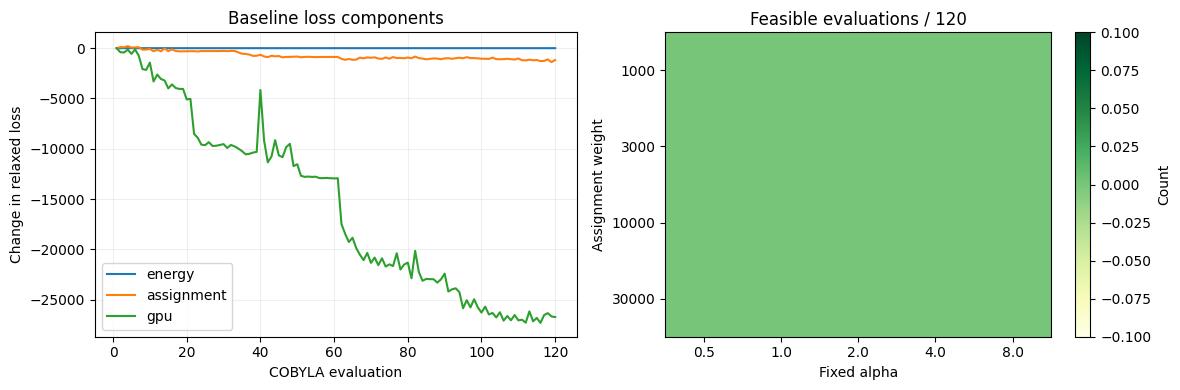

In [39]:
from src.quantum.pce_diagnostics import (
    run_fixed_alpha_penalty_trace,
    split_scheduling_qubo,
)
from src.quantum.benchmarking import evaluate_physical_schedule
from src.quantum.qubo_builder import qubo_energy
import matplotlib.pyplot as plt

MEDIUM_INSTANCE = 'medium_24_jobs'
MEDIUM_ENERGY_DAY = 'clear_sky'
MEDIUM_GPU_UNIT = 'node'  # Change to 'node' for the finer representation.
MEDIUM_ALPHA_VALUES = (0.5, 1.0, 2.0, 4.0, 8.0)
MEDIUM_ASSIGNMENT_WEIGHTS = (1_000.0, 3_000.0, 10_000.0, 30_000.0)

medium_path = ROOT / 'data' / 'instances' / 'seren_pretrain' / MEDIUM_INSTANCE
medium_raw_jobs = pd.read_csv(medium_path / 'jobs.csv')
medium_raw_clusters = pd.read_csv(medium_path / 'clusters.csv')
medium_jobs, medium_clusters = adapt_gpu_unit(
    medium_raw_jobs,
    medium_raw_clusters,
    MEDIUM_GPU_UNIT,
)
medium_jobs['cpu_required'] = medium_jobs['cpu_required'].fillna(0.0)
medium_jobs['memory_required_gb'] = medium_jobs['memory_required_gb'].fillna(0.0)
medium_energy = node_energy_days[MEDIUM_ENERGY_DAY]
medium_effective_energy = add_effective_price_for_qubo(
    medium_energy, medium_jobs, medium_clusters
)
medium_qubo_inputs = make_effective_price_qubo_inputs(medium_effective_energy)
medium_config = ModelConfig(
    contracted_power=float(medium_clusters['capacity'].sum()) * NODE_PUE,
    renewable_price=1_000_000.0,
    peak_price=0.0,
    delta_t=DELTA_T,
    pue=NODE_PUE,
)
medium_rows = []
medium_traces = {}

for assignment_weight in MEDIUM_ASSIGNMENT_WEIGHTS:
    weights = QuboPenaltyWeights(
        assignment=assignment_weight,
        gpu_capacity=frozen_weights.gpu_capacity,
        peak_smoothing=0.0,
    )
    medium_qubo = build_scheduling_qubo(
        medium_jobs, medium_qubo_inputs, medium_clusters, medium_config, weights
    )
    components = split_scheduling_qubo(
        medium_qubo, medium_qubo_inputs, medium_clusters, medium_config, weights
    )
    qubits, labels = pauli_labels_for_qubo(medium_qubo, order=2)
    circuit, parameters = ANSATZ_BUILDERS[SELECTED_ANSATZ_ID]['builder'](
        qubits, PCE_LAYERS
    )
    evaluator = build_statevector_correlation_evaluator(circuit, parameters, labels)
    theta0 = np.random.default_rng(NODE_PCE_SEED).uniform(
        -np.pi, np.pi, len(parameters)
    )
    for alpha in MEDIUM_ALPHA_VALUES:
        trace = run_fixed_alpha_penalty_trace(
            alpha, theta0, evaluator, medium_qubo, medium_jobs,
            medium_clusters, medium_qubo.metadata['hours'],
            components, NODE_FIXED_ALPHA_CONFIG,
        )
        medium_traces[(assignment_weight, alpha)] = trace
        candidate = trace.run.selected_candidate
        counts = (
            candidate.schedule['job_id'].value_counts()
            if not candidate.schedule.empty else pd.Series(dtype=int)
        )
        missing = len(set(medium_jobs['job_id']) - set(counts.index))
        duplicates = int((counts - 1).clip(lower=0).sum())
        assignment_penalty = qubo_energy(components['assignment'], candidate.bits)
        gpu_penalty = qubo_energy(components['gpu'], candidate.bits)
        schedule_feasible = bool(candidate.validation['feasible'])
        physical_cost = (
            evaluate_physical_schedule(
                candidate.schedule, medium_energy, delta_t=1.0
            )[1]['physical_total_cost']
            if schedule_feasible else np.nan
        )
        feasible_evaluations = trace.evaluations.loc[
            trace.evaluations['schedule_feasible'], 'evaluation'
        ]
        medium_rows.append({
            'gpu_unit': MEDIUM_GPU_UNIT,
            'assignment_weight': assignment_weight,
            'alpha': alpha,
            'gpu_weight': weights.gpu_capacity,
            'assignment_variables': medium_qubo.metadata['num_assignment_variables'],
            'slack_variables': medium_qubo.metadata['num_slack_variables'],
            'pce_qubits': qubits,
            'feasible_evaluations': len(feasible_evaluations),
            'first_feasible_evaluation': (
                feasible_evaluations.min() if len(feasible_evaluations) else np.nan
            ),
            'schedule_feasible': schedule_feasible,
            'full_qubo_feasible': (
                schedule_feasible and abs(assignment_penalty) < 1e-6
                and abs(gpu_penalty) < 1e-6
            ),
            'missing_jobs': missing,
            'duplicate_jobs': duplicates,
            'decoded_assignment_penalty': assignment_penalty,
            'decoded_gpu_penalty': gpu_penalty,
            'physical_total_cost': physical_cost,
        })
    print(f'Completed assignment weight {assignment_weight:g}', flush=True)

medium_weight_results = pd.DataFrame(medium_rows)
print(
    f'{MEDIUM_GPU_UNIT}: {int(medium_weight_results.schedule_feasible.sum())} '
    f'schedule-feasible combinations out of {len(medium_weight_results)}'
)
display(medium_weight_results[[
    'gpu_unit', 'assignment_weight', 'alpha', 'feasible_evaluations',
    'missing_jobs', 'duplicate_jobs', 'decoded_assignment_penalty',
    'decoded_gpu_penalty', 'schedule_feasible', 'full_qubo_feasible',
    'physical_total_cost', 'pce_qubits',
]])

baseline = medium_traces[(MEDIUM_ASSIGNMENT_WEIGHTS[0], MEDIUM_ALPHA_VALUES[0])].evaluations
display(pd.DataFrame([{
    'term': term,
    'first_relaxed_loss': baseline[f'relaxed_{term}'].iloc[0],
    'last_relaxed_loss': baseline[f'relaxed_{term}'].iloc[-1],
    'change': baseline[f'relaxed_{term}'].iloc[-1] - baseline[f'relaxed_{term}'].iloc[0],
} for term in ('energy', 'assignment', 'gpu')]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for term in ('energy', 'assignment', 'gpu'):
    values = baseline[f'relaxed_{term}']
    axes[0].plot(baseline['evaluation'], values - values.iloc[0], label=term)
axes[0].set(xlabel='COBYLA evaluation', ylabel='Change in relaxed loss', title='Baseline loss components')
axes[0].legend()
axes[0].grid(alpha=0.2)
feasible_grid = medium_weight_results.pivot(
    index='assignment_weight', columns='alpha', values='feasible_evaluations'
)
image = axes[1].imshow(feasible_grid.to_numpy(), cmap='YlGn', aspect='auto', vmin=0)
axes[1].set(
    xticks=range(len(feasible_grid.columns)),
    yticks=range(len(feasible_grid.index)),
    xticklabels=feasible_grid.columns,
    yticklabels=[f'{weight:g}' for weight in feasible_grid.index],
    xlabel='Fixed alpha', ylabel='Assignment weight', title='Feasible evaluations / 120',
)
fig.colorbar(image, ax=axes[1], label='Count')
fig.tight_layout()
plt.show()


## Step 8.1: remove the GPU penalty from the PCE objective

Repeat the medium-instance weight/alpha grid with `gpu_capacity=0`. This removes both the GPU penalty and its slack variables from the QUBO, while keeping the instance, energy term, assignment weights, alpha values, ansatz, random seed, and evaluation budget aligned with Step 8. The reduced qubit count means the theta vectors are shorter, as expected.

This is an ablation, not a claim that GPU capacity can be ignored. Every decoded theta candidate is checked against the original raw GPU requirements and capacities. Direct feasibility is preferred; otherwise only no-missing, raw-GPU-feasible candidates are eligible for duplicate-only repair.

In [40]:
from src.quantum.pce_repair import (
    select_direct_or_repaired_schedule,
    trace_physical_diagnostics,
)

medium_no_gpu_traces = {}
medium_no_gpu_rows = []
for assignment_weight in MEDIUM_ASSIGNMENT_WEIGHTS:
    no_gpu_weights = QuboPenaltyWeights(
        assignment=assignment_weight,
        gpu_capacity=0.0,
        peak_smoothing=0.0,
    )
    no_gpu_qubo = build_scheduling_qubo(
        medium_jobs, medium_qubo_inputs, medium_clusters,
        medium_config, no_gpu_weights,
    )
    no_gpu_components = split_scheduling_qubo(
        no_gpu_qubo, medium_qubo_inputs, medium_clusters,
        medium_config, no_gpu_weights,
    )
    no_gpu_qubits, no_gpu_labels = pauli_labels_for_qubo(
        no_gpu_qubo, order=2
    )
    no_gpu_circuit, no_gpu_parameters = ANSATZ_BUILDERS[
        SELECTED_ANSATZ_ID
    ]['builder'](no_gpu_qubits, PCE_LAYERS)
    no_gpu_evaluator = build_statevector_correlation_evaluator(
        no_gpu_circuit, no_gpu_parameters, no_gpu_labels
    )
    no_gpu_theta0 = np.random.default_rng(NODE_PCE_SEED).uniform(
        -np.pi, np.pi, len(no_gpu_parameters)
    )
    for alpha in MEDIUM_ALPHA_VALUES:
        trace = run_fixed_alpha_penalty_trace(
            alpha, no_gpu_theta0, no_gpu_evaluator, no_gpu_qubo,
            medium_jobs, medium_clusters, no_gpu_qubo.metadata['hours'],
            no_gpu_components, NODE_FIXED_ALPHA_CONFIG,
        )
        medium_no_gpu_traces[(assignment_weight, alpha)] = trace
        physical_trace = trace_physical_diagnostics(
            trace, medium_raw_jobs, medium_raw_clusters,
            no_gpu_qubo.metadata['hours'],
        )
        selection = select_direct_or_repaired_schedule(
            trace, medium_raw_jobs, medium_raw_clusters,
            medium_effective_energy, no_gpu_qubo.metadata['hours'],
            delta_t=DELTA_T,
        )
        metrics = selection.physical_metrics or {}
        medium_no_gpu_rows.append({
            'gpu_unit': MEDIUM_GPU_UNIT,
            'gpu_penalty_weight': 0.0,
            'assignment_weight': assignment_weight,
            'alpha': alpha,
            'assignment_variables': no_gpu_qubo.metadata['num_assignment_variables'],
            'slack_variables': no_gpu_qubo.metadata['num_slack_variables'],
            'pce_qubits': no_gpu_qubits,
            'optimizer_evaluations': len(trace.run.history),
            'candidate_assessments': len(physical_trace),
            'no_missing_candidates': int((physical_trace['missing_jobs'] == 0).sum()),
            'zero_missing_gpu_feasible_candidates': int((
                (physical_trace['missing_jobs'] == 0)
                & physical_trace['physical_gpu_feasible']
            ).sum()),
            'direct_feasible_candidates': selection.direct_candidate_count,
            'duplicate_only_repairable_candidates': selection.repairable_candidate_count,
            'selected_status': selection.status,
            'source_evaluation': selection.source_evaluation,
            'removed_duplicate_assignments': selection.removed_assignments,
            'facility_energy_mwh': metrics.get('facility_energy_mwh', np.nan),
            'renewable_energy_mwh': metrics.get('renewable_energy_mwh', np.nan),
            'grid_energy_mwh': metrics.get('grid_energy_mwh', np.nan),
            'physical_total_cost': metrics.get('physical_total_cost', np.nan),
        })
    print(f'Completed no-GPU-penalty assignment weight {assignment_weight:g}', flush=True)

medium_no_gpu_results = pd.DataFrame(medium_no_gpu_rows)
display(medium_no_gpu_results.sort_values(
    ['selected_status', 'physical_total_cost'], na_position='last'
))


Completed no-GPU-penalty assignment weight 1000
Completed no-GPU-penalty assignment weight 3000
Completed no-GPU-penalty assignment weight 10000
Completed no-GPU-penalty assignment weight 30000


,gpu_unit,gpu_penalty_weight,assignment_weight,alpha,assignment_variables,slack_variables,pce_qubits,theta_evaluations,no_missing_candidates,zero_missing_gpu_feasible_candidates,direct_feasible_candidates,duplicate_only_repairable_candidates,selected_status,source_evaluation,removed_duplicate_assignments,facility_energy_mwh,renewable_energy_mwh,grid_energy_mwh,physical_total_cost
0,node,0.0,1000.0,0.5,98,0,9,120,26,26,0,26,repaired,67,26,2.976,2.53720,0.43880,45.554045
5,node,0.0,3000.0,0.5,98,0,9,120,25,25,0,25,repaired,67,26,2.976,2.53720,0.43880,45.554045
10,node,0.0,10000.0,0.5,98,0,9,120,25,25,0,25,repaired,67,26,2.976,2.53720,0.43880,45.554045
15,node,0.0,30000.0,0.5,98,0,9,120,25,25,0,25,repaired,67,26,2.976,2.53720,0.43880,45.554045
1,node,0.0,1000.0,1.0,98,0,9,120,21,21,0,21,repaired,43,24,2.976,2.53703,0.43897,45.653597
6,node,0.0,3000.0,1.0,98,0,9,120,21,21,0,21,repaired,43,24,2.976,2.53703,0.43897,45.653597
11,node,0.0,10000.0,1.0,98,0,9,120,19,19,0,19,repaired,43,24,2.976,2.53703,0.43897,45.653597
16,node,0.0,30000.0,1.0,98,0,9,120,19,19,0,19,repaired,43,24,2.976,2.53703,0.43897,45.653597
3,node,0.0,1000.0,4.0,98,0,9,120,87,87,0,87,repaired,50,14,2.976,2.55399,0.42201,52.971732
8,node,0.0,3000.0,4.0,98,0,9,120,85,85,0,85,repaired,50,14,2.976,2.55399,0.42201,52.971732


### Step 8.1.1: COBYLA with 20,000 evaluations and binarization diagnostics

This run uses the medium instance at the selected GPU granularity, with the GPU penalty disabled in the QUBO but physical GPU capacity still checked after decoding. The fixed settings are assignment penalty beta = 1,000, alpha = 0.5, and COBYLA with a maximum of 20,000 objective evaluations. Exact statevector expectations are used, so there is no shot count.

After selecting the best physically eligible schedule (direct if available, otherwise duplicate-only repaired), the diagnostic reports the Pauli correlation r and soft-spin magnitude |tanh(alpha r)| for each positive assignment bit in its source candidate. It marks whether that assignment remained in the repaired schedule or was removed as a duplicate. A value near zero means the sign-based assignment decision was weak; it does not by itself establish that the repair is correct.

At alpha = 0.5, the theoretical maximum magnitude is tanh(0.5), about 0.462, because |r| cannot exceed 1. Therefore, interpret these values relative to that maximum rather than expecting them to approach 1.


In [ ]:
MEDIUM_811_ASSIGNMENT_WEIGHT = 1_000.0
MEDIUM_811_ALPHA = 0.5
MEDIUM_811_OPTIMIZER = "COBYLA"
MEDIUM_811_MAX_EVALUATIONS = 20_000
MEDIUM_811_TOLERANCE = 1e-5
MEDIUM_811_SEED = NODE_PCE_SEED

print({
    "instance": MEDIUM_INSTANCE,
    "gpu_unit": MEDIUM_GPU_UNIT,
    "assignment_weight_beta": MEDIUM_811_ASSIGNMENT_WEIGHT,
    "alpha": MEDIUM_811_ALPHA,
    "optimizer": MEDIUM_811_OPTIMIZER,
    "maximum_objective_evaluations": MEDIUM_811_MAX_EVALUATIONS,
    "statevector_shots": 0,
})


In [ ]:
from src.quantum.pce import (
    FixedAlphaConfig as SharedFixedAlphaConfig,
    build_statevector_correlation_evaluator,
    pauli_labels_for_qubo,
)
from src.quantum.pce_diagnostics import (
    run_fixed_alpha_penalty_trace,
    split_scheduling_qubo,
)
from src.quantum.pce_repair import (
    select_direct_or_repaired_schedule,
    trace_physical_diagnostics,
)
from src.quantum.qubo_builder import QuboPenaltyWeights, build_scheduling_qubo

medium_811_weights = QuboPenaltyWeights(
    assignment=MEDIUM_811_ASSIGNMENT_WEIGHT,
    gpu_capacity=0.0,
    peak_smoothing=0.0,
)
medium_811_qubo = build_scheduling_qubo(
    medium_jobs, medium_qubo_inputs, medium_clusters, medium_config,
    medium_811_weights,
)
medium_811_components = split_scheduling_qubo(
    medium_811_qubo, medium_qubo_inputs, medium_clusters, medium_config,
    medium_811_weights,
)
medium_811_qubits, medium_811_labels = pauli_labels_for_qubo(
    medium_811_qubo, order=2
)
medium_811_circuit, medium_811_parameters = ANSATZ_BUILDERS[
    SELECTED_ANSATZ_ID
]["builder"](medium_811_qubits, PCE_LAYERS)
medium_811_evaluator = build_statevector_correlation_evaluator(
    medium_811_circuit, medium_811_parameters, medium_811_labels
)
medium_811_theta0 = np.random.default_rng(MEDIUM_811_SEED).uniform(
    -np.pi, np.pi, len(medium_811_parameters)
)

medium_811_trace = run_fixed_alpha_penalty_trace(
    MEDIUM_811_ALPHA,
    medium_811_theta0,
    medium_811_evaluator,
    medium_811_qubo,
    medium_jobs,
    medium_clusters,
    medium_811_qubo.metadata["hours"],
    medium_811_components,
    SharedFixedAlphaConfig(
        maxiter=MEDIUM_811_MAX_EVALUATIONS,
        tolerance=MEDIUM_811_TOLERANCE,
        optimizer=MEDIUM_811_OPTIMIZER,
    ),
)
medium_811_physical_trace = trace_physical_diagnostics(
    medium_811_trace,
    medium_raw_jobs,
    medium_raw_clusters,
    medium_811_qubo.metadata["hours"],
)
medium_811_selection = select_direct_or_repaired_schedule(
    medium_811_trace,
    medium_raw_jobs,
    medium_raw_clusters,
    medium_effective_energy,
    medium_811_qubo.metadata["hours"],
    delta_t=DELTA_T,
)

medium_811_source_evaluation = medium_811_selection.source_evaluation
if medium_811_source_evaluation is None:
    raise RuntimeError("No direct or duplicate-only-repairable candidate was selected.")
medium_811_source_candidate = medium_811_trace.candidates[
    medium_811_source_evaluation - 1
]
medium_811_retained = {
    (row.job_id, row.assigned_cluster, int(row.start_hour))
    for row in medium_811_selection.schedule.itertuples(index=False)
}

medium_811_assignment_rows = []
for variable_index, variable in enumerate(medium_811_qubo.variables):
    if variable["variable_type"] != "assignment" or medium_811_source_candidate.bits[variable_index] != 1:
        continue
    assignment_key = (
        variable["job_id"], variable["cluster"], int(variable["start"])
    )
    raw_correlation = float(medium_811_source_candidate.correlations[variable_index])
    soft_spin = float(medium_811_source_candidate.soft_spins[variable_index])
    medium_811_assignment_rows.append({
        "job_id": variable["job_id"],
        "cluster": variable["cluster"],
        "start": int(variable["start"]),
        "raw_correlation_r": raw_correlation,
        "soft_spin_z": soft_spin,
        "binarization_magnitude_abs_z": abs(soft_spin),
        "repair_disposition": (
            "retained" if assignment_key in medium_811_retained
            else "removed_duplicate"
        ),
    })

medium_811_binarization = pd.DataFrame(medium_811_assignment_rows)
medium_811_binarization_summary = (
    medium_811_binarization.groupby("repair_disposition")
    .agg(
        assignment_bits=("job_id", "size"),
        mean_abs_correlation=("raw_correlation_r", lambda values: values.abs().mean()),
        median_abs_correlation=("raw_correlation_r", lambda values: values.abs().median()),
        min_abs_correlation=("raw_correlation_r", lambda values: values.abs().min()),
        mean_binarization_magnitude=("binarization_magnitude_abs_z", "mean"),
        median_binarization_magnitude=("binarization_magnitude_abs_z", "median"),
        min_binarization_magnitude=("binarization_magnitude_abs_z", "min"),
    )
    .reset_index()
)

medium_811_metrics = medium_811_selection.physical_metrics or {}
medium_811_result_summary = pd.DataFrame([{
    "optimizer": MEDIUM_811_OPTIMIZER,
    "optimizer_evaluations": int(medium_811_trace.run.optimization.nfev),
    "optimizer_status": int(medium_811_trace.run.optimization.status),
    "optimizer_success": bool(medium_811_trace.run.optimization.success),
    "stopping_message": str(medium_811_trace.run.optimization.message),
    "source_evaluation": medium_811_source_evaluation,
    "selected_status": medium_811_selection.status,
    "direct_feasible_candidates": int(
        (medium_811_physical_trace["category"] == "direct_feasible").sum()
    ),
    "duplicate_only_repairable_candidates": medium_811_selection.repairable_candidate_count,
    "removed_duplicate_assignments": medium_811_selection.removed_assignments,
    "physical_total_cost": medium_811_metrics.get("physical_total_cost", np.nan),
    "maximum_possible_abs_soft_spin": float(np.tanh(MEDIUM_811_ALPHA)),
}])

display(medium_811_result_summary)
display(medium_811_binarization_summary)
display(medium_811_binarization.sort_values(
    ["job_id", "start"]
).reset_index(drop=True))
display(medium_811_selection.schedule)


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for disposition, group in medium_811_binarization.groupby("repair_disposition"):
    axes[0].hist(
        group["binarization_magnitude_abs_z"],
        bins=np.linspace(0, np.tanh(MEDIUM_811_ALPHA), 11),
        alpha=0.65,
        label=disposition,
    )
axes[0].set(
    xlabel="Binarization magnitude |tanh(alpha r)|",
    ylabel="Selected assignment bits",
    title="Confidence of selected assignment bits",
)
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].scatter(
    medium_811_binarization["raw_correlation_r"],
    medium_811_binarization["binarization_magnitude_abs_z"],
    c=medium_811_binarization["repair_disposition"].map({
        "retained": "#287a5b",
        "removed_duplicate": "#c45b39",
    }),
    alpha=0.8,
)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(
    xlabel="Raw Pauli correlation r",
    ylabel="Binarization magnitude |tanh(alpha r)|",
    title="Correlation strength of decoded positive bits",
)
axes[1].grid(alpha=0.2)
fig.tight_layout()
plt.show()


### Step 8.2: ansatz, layer, penalty-weight, alpha, and shot study

Use Step 8.1 to select the experiment settings, then test finite-shot PCE on the same medium instance with the GPU penalty omitted from the objective. In Step 8.1, alpha=4 produced the largest pool of no-missing, physically GPU-feasible candidates; alpha=0.5 produced the lowest-cost repaired schedule. Both are retained to compare feasibility yield with energy quality. The assignment penalty weight (beta_assign, the assignment Lagrangian coefficient) has no decisive winner in Step 8.1. The top-ranked value is reported, but all four tested values are screened to test sensitivity rather than treating the near-tie as a settled optimum.

The screening compares the three ansatz families already defined in this notebook at one and two ansatz layers, all four assignment penalty weights, and both selected alpha values. Layer counts are builder-specific and do not imply identical circuit depth across ansatz families. COBYLA receives up to 600 objective evaluations per configuration. The six best ansatz/layer structures are then rerun at a higher shot count.

Shots are not used by the existing exact statevector experiment: it computes expectation values analytically from the state, so its shot count is zero. Here we emulate finite-shot measurements by sampling from statevector probabilities. Each PCE objective evaluation uses three measurement settings (X, Y, and Z); shots_per_setting is the number of samples for each setting, not the total across all three. The PCE labels are homogeneous two-body strings, so strings sharing an axis can be measured in the same setting.

The first-stage grid has 48 configurations and the second stage adds up to six finalists: at 600 evaluations each, at most 32,400 optimizer evaluations. At 256 shots for screening and 1,024 for finalists, this is about 33.2 million simulated measurement shots. These are finite-shot statevector simulations, not QPU runs.

In [41]:
# Select alpha settings from Step 8.1 using feasibility yield first, physical cost second.
alpha_selection = (
    medium_no_gpu_results.groupby("alpha", as_index=False)
    .agg(
        direct_feasible=("direct_feasible_candidates", "sum"),
        repairable_candidates=("duplicate_only_repairable_candidates", "sum"),
        best_repaired_cost=("physical_total_cost", "min"),
    )
    .sort_values(
        ["direct_feasible", "repairable_candidates", "best_repaired_cost"],
        ascending=[False, False, True],
        na_position="last",
    )
)
alpha_yield_choice = float(alpha_selection.iloc[0]["alpha"])
alpha_cost_choice = float(
    alpha_selection.sort_values("best_repaired_cost", na_position="last").iloc[0]["alpha"]
)
MEDIUM_82_ALPHA_VALUES = tuple(sorted({alpha_yield_choice, alpha_cost_choice}))

# The assignment-weight results are close, so keep all tested weights for sensitivity analysis.
beta_selection = (
    medium_no_gpu_results.groupby("assignment_weight", as_index=False)
    .agg(
        direct_feasible=("direct_feasible_candidates", "sum"),
        repairable_candidates=("duplicate_only_repairable_candidates", "sum"),
        best_repaired_cost=("physical_total_cost", "min"),
    )
    .sort_values(
        ["direct_feasible", "repairable_candidates", "best_repaired_cost", "assignment_weight"],
        ascending=[False, False, True, True],
        na_position="last",
    )
)
beta_primary_choice = float(beta_selection.iloc[0]['assignment_weight'])
MEDIUM_82_ASSIGNMENT_WEIGHTS = tuple(sorted(MEDIUM_ASSIGNMENT_WEIGHTS))

MEDIUM_82_ANSATZ_IDS = tuple(ANSATZ_BUILDERS)
MEDIUM_82_LAYERS = (1, 2)
MEDIUM_82_SCREENING_SHOTS = 256
MEDIUM_82_FINALIST_SHOTS = 1024
MEDIUM_82_MAXITER = 600
MEDIUM_82_FINALIST_COUNT = 6
MEDIUM_82_SEED = 8232026

display(alpha_selection)
display(beta_selection)
print({
    "alpha_selected_for_candidate_yield": alpha_yield_choice,
    "alpha_selected_for_repaired_energy": alpha_cost_choice,
    "alpha_values_to_test": MEDIUM_82_ALPHA_VALUES,
    "top_ranked_assignment_weight": beta_primary_choice,
    "assignment_weights_to_test": MEDIUM_82_ASSIGNMENT_WEIGHTS,
    "ansatz_families": MEDIUM_82_ANSATZ_IDS,
    "layers": MEDIUM_82_LAYERS,
    "screening_configurations": (
        len(MEDIUM_82_ANSATZ_IDS) * len(MEDIUM_82_LAYERS)
        * len(MEDIUM_82_ASSIGNMENT_WEIGHTS) * len(MEDIUM_82_ALPHA_VALUES)
    ),
    "maximum_optimizer_evaluations": (
        len(MEDIUM_82_ANSATZ_IDS) * len(MEDIUM_82_LAYERS)
        * len(MEDIUM_82_ASSIGNMENT_WEIGHTS) * len(MEDIUM_82_ALPHA_VALUES)
        + MEDIUM_82_FINALIST_COUNT
    ) * MEDIUM_82_MAXITER,
})

,alpha,direct_feasible,repairable_candidates,best_repaired_cost
3,4.0,0,342,52.971732
2,2.0,0,234,60.667824
0,0.5,0,101,45.554045
1,1.0,0,80,45.653597
4,8.0,0,31,55.937876


,assignment_weight,direct_feasible,repairable_candidates,best_repaired_cost
0,1000.0,0,198,45.554045
1,3000.0,0,198,45.554045
2,10000.0,0,196,45.554045
3,30000.0,0,196,45.554045


{'alpha_selected_for_candidate_yield': 4.0, 'alpha_selected_for_repaired_energy': 0.5, 'alpha_values_to_test': (0.5, 4.0), 'top_ranked_assignment_weight': 1000.0, 'assignment_weights_to_test': (1000.0, 3000.0, 10000.0, 30000.0), 'ansatz_families': ('legacy_chain_ry_rz_cx_v1', 'ibm_brickwork_ry_rz_cx_open_v1', 'taylor_efficient_statevector_v1'), 'layers': (1, 2), 'screening_configurations': 48, 'maximum_optimizer_evaluations': 32400}


In [42]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from src.quantum.pce import ANSATZ_BUILDERS, pauli_labels_for_qubo
from src.quantum.pce_diagnostics import run_fixed_alpha_penalty_trace, split_scheduling_qubo
from src.quantum.pce_repair import select_direct_or_repaired_schedule, trace_physical_diagnostics


def build_finite_shot_statevector_evaluator(
    circuit, parameters, pauli_labels, shots_per_setting, seed
):
    """Estimate homogeneous two-body PCE correlations with finite-shot sampling."""

    if shots_per_setting < 1:
        raise ValueError("shots_per_setting must be positive")
    qubit_count = circuit.num_qubits
    grouped_supports = {"X": [], "Y": [], "Z": []}
    for label_index, label in enumerate(pauli_labels):
        active_positions = [position for position, symbol in enumerate(label) if symbol != "I"]
        active_symbols = {label[position] for position in active_positions}
        if len(active_positions) != 2 or len(active_symbols) != 1:
            raise ValueError(f"Expected a homogeneous two-body Pauli string, got {label}")
        axis = active_symbols.pop()
        # Qiskit Pauli labels display the highest-index qubit on the left.
        qubits = [qubit_count - 1 - position for position in active_positions]
        grouped_supports[axis].append((label_index, qubits))

    rng = np.random.default_rng(seed)
    parameter_list = list(parameters)

    def evaluate(theta):
        """Return one sampled expectation estimate for each encoded QUBO spin."""

        values = np.asarray(theta, dtype=float)
        if values.shape != (len(parameter_list),):
            raise ValueError(
                f"Expected {len(parameter_list)} circuit parameters, got {values.shape}"
            )
        bound = circuit.assign_parameters(dict(zip(parameter_list, values, strict=True)))
        correlations = np.zeros(len(pauli_labels), dtype=float)
        for axis, observables in grouped_supports.items():
            measurement_basis = bound.copy()
            for qubit in range(qubit_count):
                if axis == "X":
                    measurement_basis.h(qubit)
                elif axis == "Y":
                    measurement_basis.sdg(qubit)
                    measurement_basis.h(qubit)
            probabilities = Statevector.from_instruction(measurement_basis).probabilities()
            samples = rng.choice(len(probabilities), size=shots_per_setting, p=probabilities)
            for label_index, pair in observables:
                parity = (
                    ((samples >> pair[0]) & 1) ^ ((samples >> pair[1]) & 1)
                )
                correlations[label_index] = 1.0 - 2.0 * float(parity.mean())
        return correlations

    return evaluate


# Sanity check the finite-shot estimator on a Bell pair before using it in the sweep.
bell_pair = QuantumCircuit(2)
bell_pair.h(0)
bell_pair.cx(0, 1)
bell_test = build_finite_shot_statevector_evaluator(
    bell_pair, [], ["XX", "YY", "ZZ"], shots_per_setting=128, seed=82
)
bell_correlations = bell_test(np.array([]))
np.testing.assert_allclose(bell_correlations, [1.0, -1.0, 1.0], atol=1e-12)
print("Finite-shot Pauli measurement check passed:", bell_correlations)

Finite-shot Pauli measurement check passed: [ 1. -1.  1.]


In [43]:
def run_medium_82_configuration(
    ansatz_id, layers, assignment_weight, alpha, shots_per_setting, run_seed
):
    """Run one finite-shot, fixed-alpha PCE configuration and validate its schedule."""

    weights = QuboPenaltyWeights(
        assignment=assignment_weight,
        gpu_capacity=0.0,
        peak_smoothing=0.0,
    )
    case_qubo = build_scheduling_qubo(
        medium_jobs, medium_qubo_inputs, medium_clusters, medium_config, weights
    )
    components = split_scheduling_qubo(
        case_qubo, medium_qubo_inputs, medium_clusters, medium_config, weights
    )
    qubits, labels = pauli_labels_for_qubo(case_qubo, order=2)
    circuit, parameters = ANSATZ_BUILDERS[ansatz_id]["builder"](qubits, layers)
    evaluator = build_finite_shot_statevector_evaluator(
        circuit, parameters, labels, shots_per_setting, seed=run_seed
    )
    theta0 = np.random.default_rng(
        MEDIUM_82_SEED + MEDIUM_82_ANSATZ_IDS.index(ansatz_id) * 100 + layers
    ).uniform(-np.pi, np.pi, len(parameters))
    trace = run_fixed_alpha_penalty_trace(
        alpha, theta0, evaluator, case_qubo, medium_jobs, medium_clusters,
        case_qubo.metadata["hours"], components,
        SharedFixedAlphaConfig(maxiter=MEDIUM_82_MAXITER),
    )
    physical_trace = trace_physical_diagnostics(
        trace, medium_raw_jobs, medium_raw_clusters, case_qubo.metadata["hours"]
    )
    selection = select_direct_or_repaired_schedule(
        trace, medium_raw_jobs, medium_raw_clusters, medium_effective_energy,
        case_qubo.metadata["hours"], delta_t=DELTA_T,
    )
    metrics = selection.physical_metrics or {}
    row = {
        "ansatz": ansatz_id,
        "layers": layers,
        "assignment_weight": assignment_weight,
        "alpha": alpha,
        "shots_per_setting": shots_per_setting,
        "measurement_settings_per_evaluation": 3,
        "shots_per_objective_evaluation": 3 * shots_per_setting,
        "optimizer_evaluations": len(trace.run.history),
        "candidate_assessments": len(physical_trace),
        "parameter_count": len(parameters),
        "pce_qubits": qubits,
        "direct_feasible_candidates": selection.direct_candidate_count,
        "duplicate_only_repairable_candidates": selection.repairable_candidate_count,
        "selected_status": selection.status,
        "source_evaluation": selection.source_evaluation,
        "removed_duplicate_assignments": selection.removed_assignments,
        "facility_energy_mwh": metrics.get("facility_energy_mwh", np.nan),
        "physical_total_cost": metrics.get("physical_total_cost", np.nan),
    }
    return row, selection.schedule


medium_82_screening_rows = []
medium_82_screening_schedules = {}
run_seed = MEDIUM_82_SEED

for ansatz_id in MEDIUM_82_ANSATZ_IDS:
    for layers in MEDIUM_82_LAYERS:
        for assignment_weight in MEDIUM_82_ASSIGNMENT_WEIGHTS:
            for alpha in MEDIUM_82_ALPHA_VALUES:
                row, schedule = run_medium_82_configuration(
                    ansatz_id, layers, assignment_weight, alpha,
                    MEDIUM_82_SCREENING_SHOTS, run_seed,
                )
                run_seed += 1
                medium_82_screening_rows.append(row)
                key = (ansatz_id, layers, assignment_weight, alpha)
                medium_82_screening_schedules[key] = schedule
        print(f"Screened {ansatz_id}, layers={layers}", flush=True)

medium_82_screening_results = pd.DataFrame(medium_82_screening_rows)
ranked_screening = medium_82_screening_results.sort_values(
    ["direct_feasible_candidates", "duplicate_only_repairable_candidates", "physical_total_cost"],
    ascending=[False, False, True],
    na_position="last",
)
medium_82_finalists = (
    ranked_screening.drop_duplicates(["ansatz", "layers"])
    .head(MEDIUM_82_FINALIST_COUNT)
    .reset_index(drop=True)
)

medium_82_finalist_rows = []
medium_82_finalist_schedules = {}
for finalist in medium_82_finalists.itertuples(index=False):
    row, schedule = run_medium_82_configuration(
        finalist.ansatz, int(finalist.layers), float(finalist.assignment_weight),
        float(finalist.alpha), MEDIUM_82_FINALIST_SHOTS, run_seed,
    )
    run_seed += 1
    medium_82_finalist_rows.append(row)
    medium_82_finalist_schedules[
        (finalist.ansatz, int(finalist.layers), float(finalist.assignment_weight), float(finalist.alpha))
    ] = schedule

medium_82_results = pd.concat(
    [
        medium_82_screening_results.assign(stage="screening"),
        pd.DataFrame(medium_82_finalist_rows).assign(stage="higher_shots"),
    ],
    ignore_index=True,
)
display(medium_82_results[[
    "stage", "ansatz", "layers", "assignment_weight", "alpha",
    "shots_per_setting", "shots_per_objective_evaluation", "optimizer_evaluations",
    "candidate_assessments", "direct_feasible_candidates",
    "duplicate_only_repairable_candidates", "selected_status",
    "removed_duplicate_assignments", "physical_total_cost",
]].sort_values(
    ["stage", "ansatz", "layers", "physical_total_cost"], na_position="last"
))
display(medium_82_finalists[[
    "ansatz", "layers", "assignment_weight", "alpha",
    "direct_feasible_candidates", "duplicate_only_repairable_candidates",
    "physical_total_cost",
]])

Screened legacy_chain_ry_rz_cx_v1, layers=1
Screened legacy_chain_ry_rz_cx_v1, layers=2
Screened ibm_brickwork_ry_rz_cx_open_v1, layers=1
Screened ibm_brickwork_ry_rz_cx_open_v1, layers=2
Screened taylor_efficient_statevector_v1, layers=1
Screened taylor_efficient_statevector_v1, layers=2


,stage,ansatz,layers,assignment_weight,alpha,shots_per_setting,shots_per_objective_evaluation,optimizer_evaluations,direct_feasible_candidates,duplicate_only_repairable_candidates,selected_status,removed_duplicate_assignments,physical_total_cost
52,higher_shots,ibm_brickwork_ry_rz_cx_open_v1,1,1000.0,4.0,1024,3072,165,0,48,repaired,23,58.147097
51,higher_shots,ibm_brickwork_ry_rz_cx_open_v1,2,3000.0,4.0,1024,3072,339,0,1,repaired,26,77.156139
50,higher_shots,legacy_chain_ry_rz_cx_v1,1,1000.0,4.0,1024,3072,348,0,2,repaired,20,96.551291
48,higher_shots,legacy_chain_ry_rz_cx_v1,2,3000.0,0.5,1024,3072,471,0,198,repaired,22,55.503722
53,higher_shots,taylor_efficient_statevector_v1,1,3000.0,0.5,1024,3072,119,0,8,repaired,28,82.178301
49,higher_shots,taylor_efficient_statevector_v1,2,3000.0,4.0,1024,3072,281,0,40,repaired,28,50.280294
16,screening,ibm_brickwork_ry_rz_cx_open_v1,1,1000.0,0.5,256,768,161,0,45,repaired,23,46.525690
20,screening,ibm_brickwork_ry_rz_cx_open_v1,1,10000.0,0.5,256,768,182,0,33,repaired,38,49.244574
18,screening,ibm_brickwork_ry_rz_cx_open_v1,1,3000.0,0.5,256,768,160,0,30,repaired,26,51.367925
23,screening,ibm_brickwork_ry_rz_cx_open_v1,1,30000.0,4.0,256,768,167,0,45,repaired,20,53.958237


,ansatz,layers,assignment_weight,alpha,direct_feasible_candidates,duplicate_only_repairable_candidates,physical_total_cost
0,legacy_chain_ry_rz_cx_v1,2,3000.0,0.5,0,246,59.752358
1,taylor_efficient_statevector_v1,2,3000.0,4.0,0,83,46.565245
2,legacy_chain_ry_rz_cx_v1,1,1000.0,4.0,0,80,64.419211
3,ibm_brickwork_ry_rz_cx_open_v1,2,3000.0,4.0,0,75,58.537048
4,ibm_brickwork_ry_rz_cx_open_v1,1,1000.0,4.0,0,50,55.158137
5,taylor_efficient_statevector_v1,1,3000.0,0.5,0,32,69.905412


## Step 9: physical validation and duplicate-only repair

Every theta evaluation is assessed in the following order:

1. Prefer schedules that already assign every job exactly once and respect physical GPU capacity.
2. If no directly feasible schedule exists, consider only candidates with no missing jobs, at least one duplicate, and no physical GPU-capacity violation.
3. Keep the lowest-effective-cost assignment for each duplicated job, validate the repaired schedule again, and compare candidates using physical energy and cost.

Node and block units are only QUBO representations. Final validation always restores `raw_gpu_num` for each job and `raw_gpu_count` for each cluster. Therefore a block-level candidate is never accepted solely because its rounded block load fits. Slack-bit equality is not part of final physical feasibility.

In [32]:
from src.quantum.pce_repair import select_direct_or_repaired_schedule

stale_traces = [
    key for key, trace in medium_traces.items()
    if (
        not getattr(trace, 'includes_terminal_sample', False)
        or len(trace.candidates) != len(trace.run.history) + 1
    )
]
if stale_traces:
    raise RuntimeError(
        'medium_traces predate terminal-sample capture. Restart the kernel, '
        'rerun Step 8, and then run Step 9.'
    )

medium_repair_rows = []
medium_selected_schedules = {}
for (assignment_weight, alpha), trace in medium_traces.items():
    selection = select_direct_or_repaired_schedule(
        trace, medium_raw_jobs, medium_raw_clusters, medium_effective_energy,
        medium_qubo.metadata['hours'], delta_t=DELTA_T,
    )
    zero_missing = int((trace.evaluations['missing_jobs'] == 0).sum())
    rejected_after_physical_check = max(
        0, zero_missing - selection.direct_candidate_count
        - selection.repairable_candidate_count,
    )
    metrics = selection.physical_metrics or {}
    medium_repair_rows.append({
        'gpu_unit': MEDIUM_GPU_UNIT,
        'assignment_weight': assignment_weight,
        'alpha': alpha,
        'optimizer_evaluations': len(trace.run.history),
        'candidate_assessments': len(trace.candidates),
        'zero_missing_candidates': zero_missing,
        'direct_feasible_candidates': selection.direct_candidate_count,
        'duplicate_only_physical_candidates': selection.repairable_candidate_count,
        'rejected_by_physical_or_other_checks': rejected_after_physical_check,
        'selected_status': selection.status,
        'source_evaluation': selection.source_evaluation,
        'removed_duplicate_assignments': selection.removed_assignments,
        'facility_energy_mwh': metrics.get('facility_energy_mwh', np.nan),
        'renewable_energy_mwh': metrics.get('renewable_energy_mwh', np.nan),
        'grid_energy_mwh': metrics.get('grid_energy_mwh', np.nan),
        'physical_total_cost': metrics.get('physical_total_cost', np.nan),
    })
    if selection.status != 'none':
        medium_selected_schedules[(assignment_weight, alpha)] = selection.schedule

medium_repair_results = pd.DataFrame(medium_repair_rows)
display(medium_repair_results.sort_values(
    ['selected_status', 'physical_total_cost'], na_position='last'
))


,gpu_unit,assignment_weight,alpha,theta_evaluations,zero_missing_candidates,direct_feasible_candidates,duplicate_only_physical_candidates,rejected_by_physical_or_other_checks,selected_status,source_evaluation,removed_duplicate_assignments,facility_energy_mwh,renewable_energy_mwh,grid_energy_mwh,physical_total_cost
10,node,10000.0,0.5,120,0,0,0,0,none,NaN,0,NaN,NaN,NaN,NaN
11,node,10000.0,1.0,120,0,0,0,0,none,NaN,0,NaN,NaN,NaN,NaN
12,node,10000.0,2.0,120,0,0,0,0,none,NaN,0,NaN,NaN,NaN,NaN
13,node,10000.0,4.0,120,0,0,0,0,none,NaN,0,NaN,NaN,NaN,NaN
17,node,30000.0,2.0,120,0,0,0,0,none,NaN,0,NaN,NaN,NaN,NaN
18,node,30000.0,4.0,120,0,0,0,0,none,NaN,0,NaN,NaN,NaN,NaN
19,node,30000.0,8.0,120,0,0,0,0,none,NaN,0,NaN,NaN,NaN,NaN
0,node,1000.0,0.5,120,21,0,21,0,repaired,95.0,22,2.976,2.31025,0.66575,62.063922
15,node,30000.0,0.5,120,27,0,27,0,repaired,106.0,16,2.976,2.22685,0.74915,72.776562
2,node,1000.0,2.0,120,52,0,52,0,repaired,105.0,25,2.976,2.18189,0.79411,74.774023


### Step 9.1: compare GPU penalty on versus off

Compare the same weight/alpha settings by direct feasibility, duplicate-only candidates passing raw GPU validation, and best physical cost after repair. The GPU-off result is not accepted unless the raw physical GPU audit passes.

In [1]:
gpu_on_comparison = medium_repair_results[[
    'assignment_weight', 'alpha', 'direct_feasible_candidates',
    'duplicate_only_physical_candidates', 'selected_status', 'physical_total_cost',
]].rename(columns={
    'direct_feasible_candidates': 'gpu_on_direct_feasible',
    'duplicate_only_physical_candidates': 'gpu_on_repairable',
    'selected_status': 'gpu_on_status',
    'physical_total_cost': 'gpu_on_physical_cost',
})
gpu_off_comparison = medium_no_gpu_results[[
    'assignment_weight', 'alpha', 'zero_missing_gpu_feasible_candidates',
    'direct_feasible_candidates', 'duplicate_only_repairable_candidates',
    'selected_status', 'physical_total_cost',
]].rename(columns={
    'zero_missing_gpu_feasible_candidates': 'gpu_off_zero_missing_gpu_feasible',
    'direct_feasible_candidates': 'gpu_off_direct_feasible',
    'duplicate_only_repairable_candidates': 'gpu_off_repairable',
    'selected_status': 'gpu_off_status',
    'physical_total_cost': 'gpu_off_physical_cost',
})
gpu_penalty_ablation_comparison = gpu_on_comparison.merge(
    gpu_off_comparison, on=['assignment_weight', 'alpha'], validate='one_to_one'
)
gpu_penalty_ablation_comparison['cost_change_off_minus_on'] = (
    gpu_penalty_ablation_comparison['gpu_off_physical_cost']
    - gpu_penalty_ablation_comparison['gpu_on_physical_cost']
)
display(gpu_penalty_ablation_comparison.sort_values(
    ['assignment_weight', 'alpha']
).reset_index(drop=True))
print({
    'gpu_on_repairable_evaluations': int(
        medium_repair_results['duplicate_only_physical_candidates'].sum()
    ),
    'gpu_off_repairable_evaluations': int(
        medium_no_gpu_results['duplicate_only_repairable_candidates'].sum()
    ),
    'gpu_on_combinations_with_repair': int(
        (medium_repair_results['selected_status'] == 'repaired').sum()
    ),
    'gpu_off_combinations_with_repair': int(
        (medium_no_gpu_results['selected_status'] == 'repaired').sum()
    ),
})


 assignment_weight  alpha  gpu_on_direct_feasible  gpu_on_repairable gpu_on_status  gpu_on_physical_cost  gpu_off_zero_missing_gpu_feasible  gpu_off_direct_feasible  gpu_off_repairable gpu_off_status  gpu_off_physical_cost  cost_change_off_minus_on
           10000.0    0.5                       0                  0          none                   NaN                                 25                        0                  25       repaired              45.554045                       NaN
           10000.0    1.0                       0                  0          none                   NaN                                 19                        0                  19       repaired              45.653597                       NaN
           10000.0    2.0                       0                  0          none                   NaN                                 59                        0                  59       repaired              60.667824                       NaN
    

{'gpu_on_repairable_evaluations': 378, 'gpu_off_repairable_evaluations': 788, 'gpu_on_combinations_with_repair': 13, 'gpu_off_combinations_with_repair': 20, 'best_gpu_on_cost': 62.063922, 'best_gpu_off_cost': 45.554045}


## Step 10: larger trace-derived and synthetic instances

This experiment extends the same fixed-alpha PCE and physical-repair methodology to two larger cases:

- `max_day_jobs`: 65 jobs sampled from the Seren trace.
- `capacity_binding_90_jobs_seed_2026`: a 90-job synthetic capacity-stress instance.

Both node and block QUBOs are supported. The preflight table reports QUBO variables, couplers, PCE qubits, and raw statevector size before optimization. `RUN_EXTENDED_FIXED_ALPHA` is disabled by default because statevector runtime grows exponentially with PCE qubits and every theta evaluation calculates one Pauli correlation per QUBO variable. Enable it only after reviewing the table. Block results are still validated using raw physical GPUs.

In [7]:
import time

from src.quantum.pce_diagnostics import (
    run_fixed_alpha_penalty_trace, split_scheduling_qubo,
)
from src.quantum.pce_repair import select_direct_or_repaired_schedule

RUN_EXTENDED_FIXED_ALPHA = True
EXTENDED_CASES = (
    ('seren_trace', 'max_day_jobs'),
    ('synthetic_stress', 'capacity_binding_90_jobs_seed_2026'),
)
EXTENDED_GPU_UNITS = ('block', 'node')
EXTENDED_ALPHA_VALUES = (0.5, 2.0, 4.0, 8.0)
EXTENDED_ENERGY_DAY = 'clear_sky'
EXTENDED_MAXITER = 120
EXTENDED_ASSIGNMENT_WEIGHT = 1_000.0
EXTENDED_STATEVECTOR_MEMORY_BUDGET_GIB = 8.0


def prepare_extended_case(instance_name: str, gpu_unit: str) -> dict:
    """Load one case and build its selected-unit QUBO and PCE mapping."""

    path = ROOT / 'data' / 'instances' / 'seren_pretrain' / instance_name
    raw_jobs = pd.read_csv(path / 'jobs.csv')
    raw_clusters = pd.read_csv(path / 'clusters.csv')
    jobs, clusters = adapt_gpu_unit(raw_jobs, raw_clusters, gpu_unit)
    jobs['cpu_required'] = jobs['cpu_required'].fillna(0.0)
    jobs['memory_required_gb'] = jobs['memory_required_gb'].fillna(0.0)
    energy = node_energy_days[EXTENDED_ENERGY_DAY]
    effective_energy = add_effective_price_for_qubo(energy, jobs, clusters)
    qubo_inputs = make_effective_price_qubo_inputs(effective_energy)
    config = ModelConfig(
        contracted_power=float(clusters['capacity'].sum()) * NODE_PUE,
        renewable_price=1_000_000.0, peak_price=0.0,
        delta_t=DELTA_T, pue=NODE_PUE,
    )
    weights = QuboPenaltyWeights(
        assignment=EXTENDED_ASSIGNMENT_WEIGHT,
        gpu_capacity=frozen_weights.gpu_capacity, peak_smoothing=0.0,
    )
    qubo = build_scheduling_qubo(jobs, qubo_inputs, clusters, config, weights)
    components = split_scheduling_qubo(
        qubo, qubo_inputs, clusters, config, weights
    )
    qubits, labels = pauli_labels_for_qubo(qubo, order=2)
    statevector_gib = 16.0 * (2 ** qubits) / (1024 ** 3)
    return {
        'raw_jobs': raw_jobs, 'raw_clusters': raw_clusters,
        'jobs': jobs, 'clusters': clusters, 'energy': effective_energy,
        'qubo': qubo, 'components': components, 'qubits': qubits,
        'labels': labels, 'statevector_gib': statevector_gib,
    }


extended_prepared = {}
preflight_rows = []
for source, instance_name in EXTENDED_CASES:
    for gpu_unit in EXTENDED_GPU_UNITS:
        case = prepare_extended_case(instance_name, gpu_unit)
        extended_prepared[(source, instance_name, gpu_unit)] = case
        preflight_rows.append({
            'source': source, 'instance': instance_name, 'gpu_unit': gpu_unit,
            'jobs': len(case['jobs']),
            'assignment_variables': case['qubo'].metadata['num_assignment_variables'],
            'slack_variables': case['qubo'].metadata['num_slack_variables'],
            'qubo_variables': case['qubo'].num_variables,
            'quadratic_couplers': len(case['qubo'].quadratic),
            'pce_qubits': case['qubits'],
            'raw_statevector_gib': case['statevector_gib'],
            'within_memory_budget': (
                case['statevector_gib'] <= EXTENDED_STATEVECTOR_MEMORY_BUDGET_GIB
            ),
        })
extended_preflight = pd.DataFrame(preflight_rows)
display(extended_preflight)

extended_rows = []
extended_traces = {}
extended_selected_schedules = {}
if not RUN_EXTENDED_FIXED_ALPHA:
    print('Extended statevector execution is disabled; review the preflight table first.')
else:
    for key, case in extended_prepared.items():
        source, instance_name, gpu_unit = key
        if case['statevector_gib'] > EXTENDED_STATEVECTOR_MEMORY_BUDGET_GIB:
            print(f'Skipping {instance_name}/{gpu_unit}: statevector memory budget exceeded.')
            continue
        circuit, parameters = ANSATZ_BUILDERS[SELECTED_ANSATZ_ID]['builder'](
            case['qubits'], PCE_LAYERS
        )
        evaluator = build_statevector_correlation_evaluator(
            circuit, parameters, case['labels']
        )
        theta0 = np.random.default_rng(NODE_PCE_SEED).uniform(
            -np.pi, np.pi, len(parameters)
        )
        for alpha in EXTENDED_ALPHA_VALUES:
            started = time.perf_counter()
            trace = run_fixed_alpha_penalty_trace(
                alpha, theta0, evaluator, case['qubo'], case['jobs'],
                case['clusters'], case['qubo'].metadata['hours'],
                case['components'],
                SharedFixedAlphaConfig(maxiter=EXTENDED_MAXITER),
            )
            extended_traces[(instance_name, gpu_unit, alpha)] = trace
            selection = select_direct_or_repaired_schedule(
                trace, case['raw_jobs'], case['raw_clusters'], case['energy'],
                case['qubo'].metadata['hours'], delta_t=DELTA_T,
            )
            metrics = selection.physical_metrics or {}
            extended_rows.append({
                'source': source, 'instance': instance_name,
                'gpu_unit': gpu_unit, 'alpha': alpha,
                'runtime_s': time.perf_counter() - started,
                'optimizer_evaluations': len(trace.run.history),
                'candidate_assessments': len(trace.candidates),
                'direct_feasible_candidates': selection.direct_candidate_count,
                'duplicate_only_physical_candidates': selection.repairable_candidate_count,
                'selected_status': selection.status,
                'removed_duplicate_assignments': selection.removed_assignments,
                'facility_energy_mwh': metrics.get('facility_energy_mwh', np.nan),
                'physical_total_cost': metrics.get('physical_total_cost', np.nan),
                'qubo_variables': case['qubo'].num_variables,
                'pce_qubits': case['qubits'],
            })
            if selection.status != 'none':
                extended_selected_schedules[(instance_name, gpu_unit, alpha)] = selection.schedule
            print(f'Completed {instance_name}/{gpu_unit}/alpha={alpha:g}', flush=True)

extended_results = pd.DataFrame(extended_rows)
if not extended_results.empty:
    display(extended_results.sort_values(['instance', 'gpu_unit', 'alpha']))


,source,instance,gpu_unit,jobs,assignment_variables,slack_variables,qubo_variables,quadratic_couplers,pce_qubits,raw_statevector_gib,within_memory_budget
0,seren_trace,max_day_jobs,block,65,246,110,356,3766,16,0.000977,True
1,seren_trace,max_day_jobs,node,65,246,198,444,5426,18,0.003906,True
2,synthetic_stress,capacity_binding_90_jobs_seed_2026,block,90,353,95,448,8676,18,0.003906,True
3,synthetic_stress,capacity_binding_90_jobs_seed_2026,node,90,353,171,524,10798,20,0.015625,True


Completed max_day_jobs/block/alpha=0.5


Completed max_day_jobs/block/alpha=2


Completed max_day_jobs/block/alpha=4


Completed max_day_jobs/block/alpha=8


Completed max_day_jobs/node/alpha=0.5


... (8 outputs left out)

Completed capacity_binding_90_jobs_seed_2026/node/alpha=2


Completed capacity_binding_90_jobs_seed_2026/node/alpha=4


Completed capacity_binding_90_jobs_seed_2026/node/alpha=8


,source,instance,gpu_unit,alpha,runtime_s,theta_evaluations,direct_feasible_candidates,duplicate_only_physical_candidates,selected_status,removed_duplicate_assignments,facility_energy_mwh,physical_total_cost,qubo_variables,pce_qubits
8,synthetic_stress,capacity_binding_90_jobs_seed_2026,block,0.5,70.444510,120,0,0,none,0,NaN,NaN,448,18
9,synthetic_stress,capacity_binding_90_jobs_seed_2026,block,2.0,78.327856,120,0,0,none,0,NaN,NaN,448,18
10,synthetic_stress,capacity_binding_90_jobs_seed_2026,block,4.0,112.203626,120,0,0,none,0,NaN,NaN,448,18
11,synthetic_stress,capacity_binding_90_jobs_seed_2026,block,8.0,77.414013,120,0,0,none,0,NaN,NaN,448,18
12,synthetic_stress,capacity_binding_90_jobs_seed_2026,node,0.5,130.582909,120,0,0,none,0,NaN,NaN,524,20
13,synthetic_stress,capacity_binding_90_jobs_seed_2026,node,2.0,132.387728,120,0,0,none,0,NaN,NaN,524,20
14,synthetic_stress,capacity_binding_90_jobs_seed_2026,node,4.0,132.627993,120,0,0,none,0,NaN,NaN,524,20
15,synthetic_stress,capacity_binding_90_jobs_seed_2026,node,8.0,128.200731,120,0,0,none,0,NaN,NaN,524,20
0,seren_trace,max_day_jobs,block,0.5,21.377899,120,0,0,none,0,NaN,NaN,356,16
1,seren_trace,max_day_jobs,block,2.0,19.175069,120,0,0,none,0,NaN,NaN,356,16


## Step 11: why larger instances do not become feasible

The previous result only says that no direct or repairable schedule was found. This section classifies every theta evaluation to identify the blocking condition:

- `missing_jobs`: at least one job was never selected, so duplicate removal cannot repair the schedule.
- `physical_gpu_violation`: every job is present, but raw GPU capacity is exceeded.
- `duplicate_only_repairable`: every job is present, raw GPU capacity is respected, and only duplicates remain.
- `direct_feasible`: exactly one assignment per job and physical GPU feasibility.

The closest candidate is selected lexicographically: first minimize missing jobs, then violated GPU slots, and finally duplicated assignments. The plots show whether COBYLA progressively improves job coverage or reaches a plateau.


Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/juanparrado/.cache/fontconfig
	/Users/juanparrado/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/juanparrado/.cache/fontconfig
	/Users/juanparrado/.fontconfig


,source,instance,gpu_unit,alpha,evaluations,missing_job_evaluations,zero_missing_gpu_violations,duplicate_only_repairable,direct_feasible,minimum_missing_jobs,closest_evaluation,closest_missing_jobs,closest_duplicate_assignments,closest_gpu_violated_slots,closest_gpu_max_excess,assignment_loss_change,gpu_loss_change
8,synthetic_stress,capacity_binding_90_jobs_seed_2026,block,0.5,120,120,0,0,0,3,2,3,101,8,3400.0,-6465.633446,-938.409636
9,synthetic_stress,capacity_binding_90_jobs_seed_2026,block,2.0,120,120,0,0,0,2,6,2,103,8,3208.0,-19324.086297,-2989.423601
10,synthetic_stress,capacity_binding_90_jobs_seed_2026,block,4.0,120,120,0,0,0,2,6,2,103,8,3208.0,-30073.333977,-3395.176494
11,synthetic_stress,capacity_binding_90_jobs_seed_2026,block,8.0,120,120,0,0,0,2,70,2,79,5,1304.0,-57603.619785,-4791.385933
12,synthetic_stress,capacity_binding_90_jobs_seed_2026,node,0.5,120,120,0,0,0,5,1,5,89,8,2208.0,-2712.918269,-106140.882553
13,synthetic_stress,capacity_binding_90_jobs_seed_2026,node,2.0,120,120,0,0,0,5,1,5,89,8,2208.0,-8175.413667,-382960.768826
14,synthetic_stress,capacity_binding_90_jobs_seed_2026,node,4.0,120,120,0,0,0,5,1,5,89,8,2208.0,-6740.483361,-631209.653561
15,synthetic_stress,capacity_binding_90_jobs_seed_2026,node,8.0,120,120,0,0,0,5,28,5,93,7,1632.0,-4584.633065,-749514.965581
0,seren_trace,max_day_jobs,block,0.5,120,120,0,0,0,5,24,5,62,2,832.0,-5200.444336,-520.753986
1,seren_trace,max_day_jobs,block,2.0,120,120,0,0,0,4,114,4,50,3,896.0,-12924.204187,-1268.066690


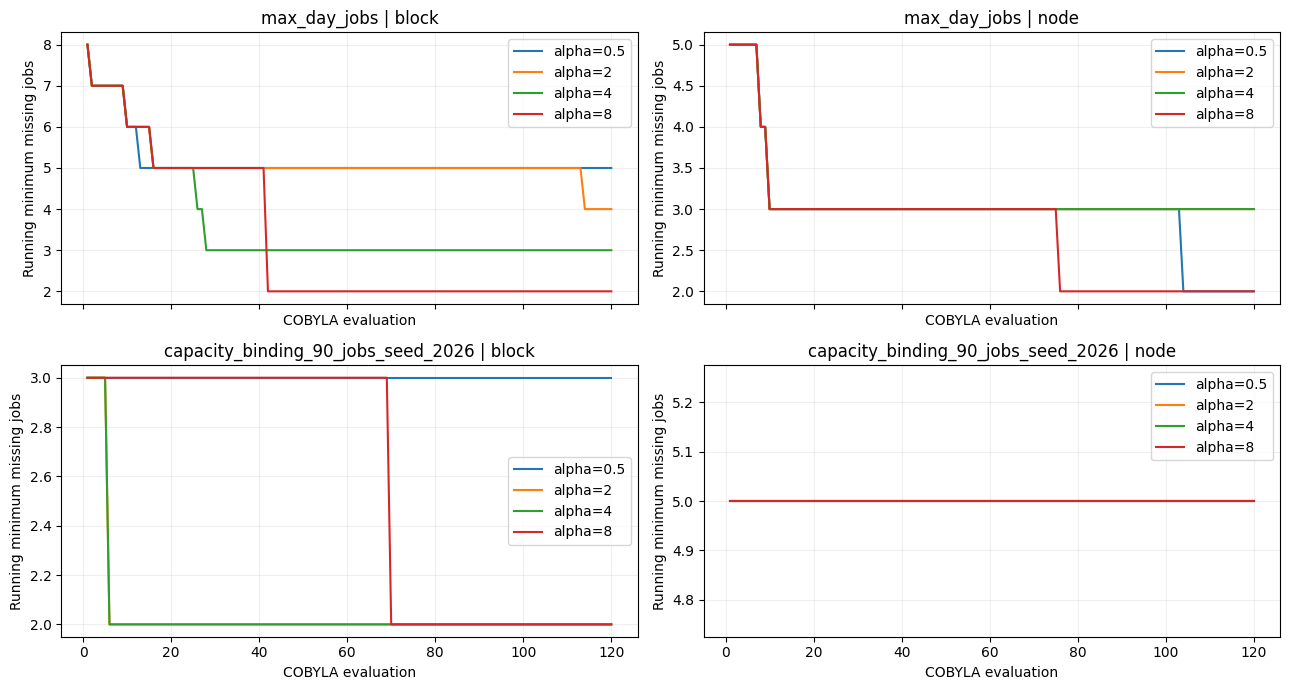

In [8]:
import matplotlib.pyplot as plt

from src.quantum.pce_repair import trace_physical_diagnostics

if not extended_traces:
    raise RuntimeError(
        'No extended traces are available. Enable RUN_EXTENDED_FIXED_ALPHA '
        'and rerun Step 10 before running this section.'
    )

extended_diagnostic_frames = {}
extended_diagnostic_rows = []
for (instance_name, gpu_unit, alpha), trace in extended_traces.items():
    source, case = next(
        (source, case)
        for (source, name, unit), case in extended_prepared.items()
        if name == instance_name and unit == gpu_unit
    )
    diagnostics = trace_physical_diagnostics(
        trace, case['raw_jobs'], case['raw_clusters'],
        case['qubo'].metadata['hours'],
    )
    extended_diagnostic_frames[(instance_name, gpu_unit, alpha)] = diagnostics
    counts = diagnostics['category'].value_counts()
    closest = diagnostics.sort_values([
        'missing_jobs', 'physical_gpu_violated_slots',
        'duplicate_assignments', 'assignment_errors', 'evaluation',
    ]).iloc[0]
    extended_diagnostic_rows.append({
        'source': source, 'instance': instance_name,
        'gpu_unit': gpu_unit, 'alpha': alpha,
        'evaluations': len(diagnostics),
        'missing_job_evaluations': int(counts.get('missing_jobs', 0)),
        'zero_missing_gpu_violations': int(counts.get('physical_gpu_violation', 0)),
        'duplicate_only_repairable': int(counts.get('duplicate_only_repairable', 0)),
        'direct_feasible': int(counts.get('direct_feasible', 0)),
        'minimum_missing_jobs': int(diagnostics['missing_jobs'].min()),
        'closest_evaluation': int(closest.evaluation),
        'closest_missing_jobs': int(closest.missing_jobs),
        'closest_duplicate_assignments': int(closest.duplicate_assignments),
        'closest_gpu_violated_slots': int(closest.physical_gpu_violated_slots),
        'closest_gpu_max_excess': float(closest.physical_gpu_max_excess),
        'assignment_loss_change': float(
            diagnostics['relaxed_assignment'].iloc[-1]
            - diagnostics['relaxed_assignment'].iloc[0]
        ),
        'gpu_loss_change': float(
            diagnostics['relaxed_gpu'].iloc[-1]
            - diagnostics['relaxed_gpu'].iloc[0]
        ),
    })

extended_diagnostics = pd.DataFrame(extended_diagnostic_rows)
display(extended_diagnostics.sort_values(['instance', 'gpu_unit', 'alpha']))

instances = [name for _, name in EXTENDED_CASES]
fig, axes = plt.subplots(
    len(instances), len(EXTENDED_GPU_UNITS), figsize=(13, 7),
    sharex=True, squeeze=False,
)
for row, instance_name in enumerate(instances):
    for column, gpu_unit in enumerate(EXTENDED_GPU_UNITS):
        axis = axes[row, column]
        for alpha in EXTENDED_ALPHA_VALUES:
            diagnostics = extended_diagnostic_frames[(instance_name, gpu_unit, alpha)]
            axis.plot(
                diagnostics['evaluation'],
                diagnostics['running_min_missing_jobs'],
                label=f'alpha={alpha:g}',
            )
        axis.set_title(f'{instance_name} | {gpu_unit}')
        axis.set_xlabel('COBYLA evaluation')
        axis.set_ylabel('Running minimum missing jobs')
        axis.grid(alpha=0.2)
        axis.legend()
fig.tight_layout()
plt.show()
